# Artifacts

**Part:** I — Image quality & artifacts · **Reading time:** ~90 min · **Pass 1 overview:** [Speed, Artifacts and Safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

An **artifact** is anything in the image that is not in the patient: a ghost, a stripe, a shifted organ, a dark band. Artifacts matter for two reasons: they can hide disease, and — worse — they can *mimic* disease. Almost every MRI artifact has a clean explanation in terms of the signal equation and k-space: some function has multiplied, replaced or added to the data, and the image shows the consequence. This notebook is a catalogue: for each artifact, **what you see**, the **physical cause**, the **math** (usually via the point spread function, [Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb)), **which parameters make it better or worse**, **how to mitigate it**, and a **simulation**. The Wikipedia entry https://en.wikipedia.org/wiki/MRI_artifact is also very comprehensive.

## Learning goals

1. Identify artifacts and how to mitigate them

New in this adaptation:

2. Explain each artifact with the signal equation / k-space weighting, predict *where* it appears (readout vs phase-encoding direction) and *how large* it is (e.g. pixel shifts, ghost spacing).
3. Simulate each artifact on real k-space data or a phantom and try out the mitigation.
4. Know which protocol parameters (FOV, bandwidth, echo spacing, TE, matrix, acceleration, TR) make an artifact better or worse.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x$, $y$ | readout (frequency-encoding, FE) and phase-encoding (PE) directions | m | in the simulations: columns = readout, rows = PE |
| $k_x$, $k_y$ | k-space coordinates | m⁻¹ | |
| $m(\vec r)$, $\hat m(\vec r)$ | true object; reconstructed (artifacted) image | a.u. | |
| $M(\vec k)$, $\hat M(\vec k)$ | true and measured k-space data (not the magnetization $\vec M$) | a.u. | |
| $W(\vec k)$, $w(\vec r)$ | k-space weighting and its PSF $w=\mathcal F^{-1}\{W\}$ | –, m⁻² | |
| $N$, $N_{PE}$, $N_x$ | matrix sizes | – | 128–512 |
| $FOV$, $FOV_{FE}$, $FOV_{PE}$ | field of view (in readout / PE direction) | m | 0.2–0.45 m |
| $\Delta k$ | k-space sample spacing $=1/FOV$ | m⁻¹ | |
| $\Delta x$ | pixel size $=FOV/N$ | m | 0.5–2 mm |
| $R$ | parallel-imaging acceleration (undersampling) factor | – | 2–4 |
| $g$ | g-factor (noise amplification of parallel imaging) | – | ≥ 1 |
| $\Delta f$, $\Delta f_{cs}$, $\Delta f_r(\vec r)$ | total off-resonance; chemical shift; field-inhomogeneity off-resonance | Hz | fat ≈ −447 Hz at 3 T |
| $\Delta B_0(\vec r)$ | deviation of the static field | T | ppm of $B_0$ |
| $\chi$, $\Delta\chi$ | magnetic susceptibility; difference between two materials | – | air–tissue $\Delta\chi\approx9.4\times10^{-6}$ |
| $BW_{read}$ ($RBW$ in the original) | total receiver bandwidth | Hz | 15–250 kHz |
| $BW_{pix}=BW_{read}/N_x$ | bandwidth per pixel | Hz/pixel | 100–1000 (2DFT), 10–40 (EPI along PE) |
| $t_{esp}$ | echo spacing (EPI) | s | 0.4–1 ms |
| $N_{steps}$ | number of k-space lines skipped between consecutive EPI echoes (interleaves × R) | – | 1–4 |
| $BW_{PE}=N_{steps}/t_{esp}$ | EPI "phase-encoding bandwidth" | Hz | |
| $BW_{rf}$ | RF pulse bandwidth | Hz | 1–3 kHz |
| $\Delta z$ | slice thickness | m | 1–5 mm |
| $\Delta_{FE}$, $\Delta_{PE}$, $\Delta_{SS}$ | displacement in readout, PE and slice direction | m | |
| $TE$, $TR$, $TI$ | echo, repetition, inversion time | s | |
| $T_1$, $T_2$, $T_2^*$ | relaxation time constants | s | |
| $T_{motion}$ | period of a periodic motion (breathing ≈ 4 s, heart ≈ 1 s) | s | |
| $d_j$ | object displacement during the acquisition of PE line $j$ | m | |
| $\phi$, $\phi(x)$ | phase (error) | rad | |
| $\theta$, $b_1(\vec r)$ | flip angle; relative transmit field $B_1^+/B_{1,nominal}^+$ | rad, – | $b_1$ 0.6–1.4 at 3 T in the body |
| $C_n(\vec r)$ | receive sensitivity of coil $n$ | – | |
| $\alpha$ | gradient non-linearity coefficient (toy model) | – | few % at 20–25 cm from isocentre |
| $\sigma_n$ | noise standard deviation | a.u. | |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio | rad s⁻¹ T⁻¹, Hz/T | $\bar\gamma$ = 42.58 MHz/T |
| $B_0$ | main field | T | 1.5, 3 T |
| $i$ | imaginary unit | – | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Introduction

Many of the artifacts that occur in MRI can be understood and analyzed using the k-space perspective. In particular, they can be understood as the k-space data being modified by some function. This is described mathematically in [MRI Signal Equation](C2_MRI_Signal_Equation.ipynb), and expanded upon in the [Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb) section. Three generic "operations" on k-space cover most of this chapter:

| What happens to k-space | Image consequence | Examples |
|---|---|---|
| **multiplied** by a weighting $W(\vec k)$ (amplitude and/or phase) | convolution with the PSF $w=\mathcal F^{-1}\{W\}$: blur, shift, ringing, ghosts | truncation, $T_2^*$ decay, off-resonance, motion, N/2 ghost |
| **sampled** too coarsely or **incompletely** | replicas → aliasing; missing-data artifacts | small FOV, parallel imaging failures |
| something is **added** (or replaced) | the FT of the added part is added to the image | spikes (stripes), RF interference (zipper), noise |

Plus a fourth class where the *encoding itself* is wrong (non-linear gradients, spatially varying off-resonance): the image is **warped**, which is no longer a convolution — we simulate those with an explicit forward model.

**Which direction?** In 2DFT, all samples of one readout line are acquired within a few ms after one excitation, while consecutive phase-encoding lines are one $TR$ (hundreds of ms) apart. Anything that changes *slowly* between lines (motion, flow, unstable hardware) therefore corrupts the **phase-encoding** direction; anything that acts *during* the readout (off-resonance, chemical shift, $T_2^*$) acts along the **readout** direction. In EPI the PE lines are only $t_{esp}$ apart, so the "slow" axis is still PE but with a very low bandwidth — off-resonance effects move to PE.

## Artifact comparison (from the original)

MRI artifacts can generally be categorized as originating from the sample, the sequence, or the system (Source in table below). The table below provides a high-level comparison of these artifacts. An extended table with the mathematical cause and the parameters that make each artifact better or worse is at the end of this notebook.

| Artifact Name | Source | Appearance | What to do? | Frequency or Phase encoding |
|---|---|---|---|---|
| Aliasing | Sequence - FOV too small, or parallel imaging failed | Signal folds across image | Increase FOV, swap PE/FE, reacquire sensitivity maps or reduce acceleration factor (parallel imaging) | Phase encoding |
| Gibbs Ringing/Truncation | Sequence - due to Fourier encoding of edges | Ripples/ringing at sharp edges | Filtering of data, decrease voxel size | N/A (both) |
| Boundary Artifacts/Partial Volume | Sequence and Sample - opposing phase of $M_{XY}$ within a voxel due to inversion or chemical shift | Artificial dark lines at tissue boundaries  | fat suppression, fat/water imaging, change inversion time | N/A |
| Fat Displacement  | Sample - chemical shift (fat)  | Shifts of fat signals in image  | Increase bandwidths, fat suppression, fat/water imaging, swap PE/FE |  Frequency encoding (2DFT), Phase encoding (EPI) |
| Off-resonance Distortion | Sample - off-resonance (e.g. magnetic susceptibility differences)  | Stretch and Compression in image | Increase bandwidths, shimming, swap PE/FE |  Frequency encoding (2DFT), Phase encoding (EPI) |
| Slice Displacement | Sample - chemical shift (fat) and off-resonance (e.g. magnetic susceptibility differences)  | Slice location shifts  | Increase RF bandwidth, shimming, use 3D scanning | N/A (slice direction) |
| T2* | Sample - magnetic susceptibility differences (e.g. implants, air) | Signal loss  | Use spin echoes, shorten TE, shimming | N/A |
| Motion/Flow | Sample - signal modulated during spatial encoding | Copies or "Ghosts" of image regions that are changing due to motion or flow | Breath-hold, gating, triggering, flow compensation, spatial saturation, swap PE/FE | Phase encoding |
| Spike Noise | System - intermittent unwanted signal | Specific spatial frequency on top of entire image | check RF hardware (loose connections, broken components) | N/A |
| RF interference/Zipper | System - unwanted frequencies received in data | Line of noisy signal on top of image | RF shielding (e.g. close door), check RF hardware, check room lights | At a specific frequency encoding location |
| Dielectric Shading | System - RF propagates unevenly, creating B1 inhomogeneity | Shading across entire image, particularly with large FOVs and higher B0 | B1-insensitive pulse sequences (e.g. adiabatic pulses), image bias field corrections | N/A |
| Gradient non-linearity | System - magnetic field gradients are not linear, especially away from isocenter | Distortion of subject, particularly near edges of large FOV | Gradient warping correction | N/A (all) |

### Sample k-space data for simulated artifacts

We use a fully sampled 2D spin-echo T1-weighted sagittal brain dataset (256 × 256 complex k-space samples). As in the original, we treat the **rows (vertical axis) as the phase-encoding direction** and the columns (horizontal) as the readout. `show_pair` is a small helper that displays log-magnitude k-space next to the image.

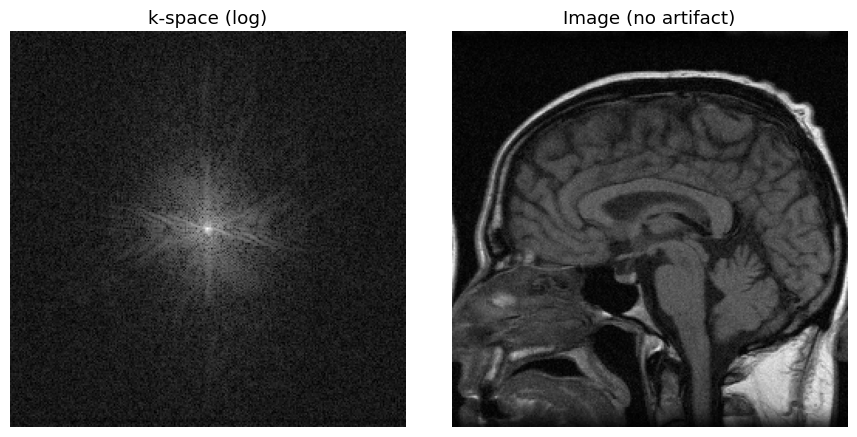

k-space size: (256, 256)   (rows = phase encoding, columns = readout)


In [2]:
# Sample k-space data for simulated artifacts
from scipy.io import loadmat

mat = loadmat("../data/se_t1_sag_data.mat")      # keys: 'data' (256 x 256 complex k-space)
kdata = mat["data"]
S = kdata.shape
im_original = mt.ifft2c(kdata)
vmax0 = np.abs(im_original).max()
kmax0 = np.abs(kdata).max()

def show_pair(K, title, img=None, vmax=vmax0, axes=None):
    """Show log|k-space| and |image| side by side. If img is None it is reconstructed from K."""
    img = mt.ifft2c(K) if img is None else img
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(9, 4.4))
    axes[0].imshow(np.log(np.abs(K) + 1e-3 * kmax0), cmap="gray"); axes[0].axis("off")
    axes[0].set_title("k-space (log)")
    axes[1].imshow(np.abs(img), cmap="gray", vmin=0, vmax=vmax); axes[1].axis("off")
    axes[1].set_title(title)
    return axes

show_pair(kdata, "Image (no artifact)")
plt.tight_layout(); plt.show()
print("k-space size:", S, "  (rows = phase encoding, columns = readout)")

The log display makes the weak outer k-space visible: the energy is concentrated at the centre (low spatial frequencies = overall contrast), the periphery carries the edges and fine detail.

## 1. Sampling artifacts — aliasing and Gibbs ringing

### 1.1 Aliasing (wrap-around)

**What you see:** anatomy from outside the FOV appears folded in on the opposite side of the image (e.g. the arms overlapping the abdomen, the nose wrapping to the back of the head).

**Cause and math:** Aliasing occurs when the FOV, determined by the sample spacing chosen in k-space ($FOV=1/\Delta k$), is too small (see [FOV and Resolution](G1_FOV_and_Resolution.ipynb)). Sampling k-space at spacing $\Delta k$ makes the PSF periodic with period $1/\Delta k$ ([I1, Section 2.3](I1_Point_Spread_Function_Analysis.ipynb)), so

$$\hat m(y)=\sum_{j=-\infty}^{\infty}m(y+j\,FOV_{PE})\quad\text{for }|y|<FOV_{PE}/2$$

In words: every location inside the reconstructed FOV receives the signal of all locations that are a whole number of FOVs away.
Where: $FOV_{PE}=1/\Delta k_y$ [m] = FOV in the phase-encoding direction; $j$ = integer.

The reason is visible in the phase-encoding patterns themselves: the $n$-th phase-encoding step imprints the phase pattern $e^{-i2\pi n\Delta k_y y}$ on the magnetization, and this pattern repeats every $1/\Delta k_y=FOV_{PE}$. Two spins one FOV apart get *identical* phases for *every* phase-encoding step, so no reconstruction can tell them apart. The following cell is a static Python port of the original's `phase_encoding_aliasing.m` (which produced animated GIFs of these patterns).

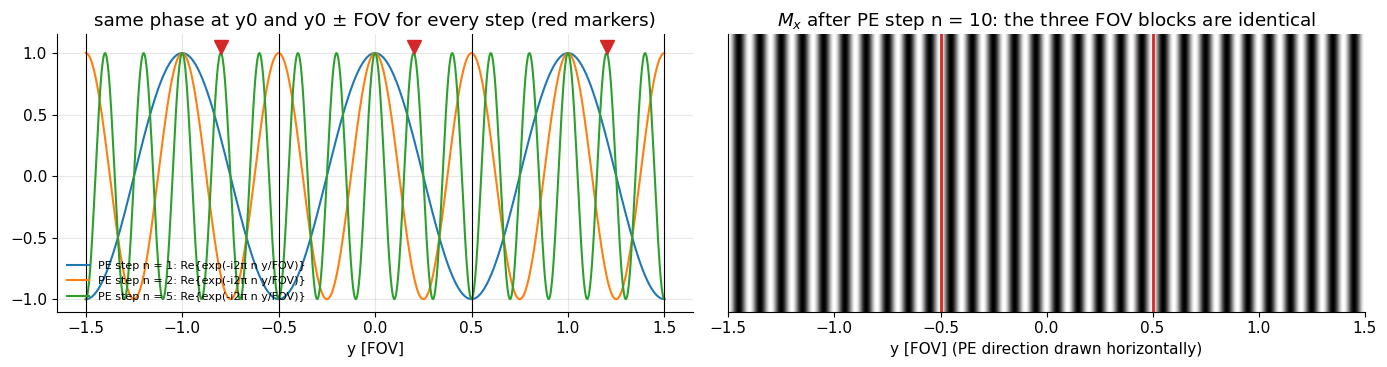

In [3]:
# Static port of phase_encoding_aliasing.m: phase-encoding patterns over 3 FOVs
y = np.linspace(-1.5, 1.5, 1201)                 # position in units of FOV_PE
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for n in [1, 2, 5]:
    ax[0].plot(y, np.real(np.exp(-1j * 2 * np.pi * n * y)), label=f"PE step n = {n}: Re{{exp(-i2π n y/FOV)}}")
for b in [-1.5, -0.5, 0.5, 1.5]:
    ax[0].axvline(b, color="k", lw=0.8)
y0 = 0.2
for j in [-1, 0, 1]:
    ax[0].plot(y0 + j, 1.05, "v", color="C3", ms=10)
ax[0].set_xlabel("y [FOV]"); ax[0].set_title("same phase at y0 and y0 ± FOV for every step (red markers)")
ax[0].legend(fontsize=8, loc="lower left")
# 2D view: real part (Mx) of the n = 10 pattern over 3 FOVs, divided into three FOV-sized blocks
X, Y = np.meshgrid(np.linspace(-0.5, 0.5, 100), y)
ax[1].imshow(np.real(np.exp(-1j * 2 * np.pi * 10 * Y)).T, cmap="gray", aspect="auto", extent=[-1.5, 1.5, -0.5, 0.5])
for b in [-0.5, 0.5]:
    ax[1].axvline(b, color="C3", lw=2)
ax[1].set_xlabel("y [FOV] (PE direction drawn horizontally)"); ax[1].set_yticks([]); ax[1].grid(False)
ax[1].set_title("$M_x$ after PE step n = 10: the three FOV blocks are identical")
plt.tight_layout(); plt.show()

Every phase-encoding pattern is periodic with period $FOV_{PE}$, so the three FOV-sized blocks look identical: an MRI scanner fundamentally cannot distinguish $y$ from $y\pm FOV$ in the phase-encoding direction.

**Why only the phase-encoding direction?** Note that in MRI, aliasing only occurs in the phase-encoding direction in practice. This is because during frequency encoding a low-pass **anti-aliasing filter** can be applied to the analog signal prior to digitization (and modern receivers oversample the readout, typically 2×, then filter digitally and discard the outer half of the image at no time cost). Frequency = position during the readout, so this truncates the bandwidth of the signal in the frequency-encode direction, which is equivalent to truncating the image. No such filter exists for phase encoding, because each PE step is a separate measurement.

![Axial abdomen image showing aliasing](../images/artifacts/abdomen_aliasing.png)

*Axial abdomen image showing aliasing artifact in the phase-encoding direction (left/right).*

The original's simulation keeps every second PE line (doubling $\Delta k_y$, halving $FOV_{PE}$) but reconstructs on the full matrix by zero-filling the missing lines. The second panel is a port of `generate_image_artifacts.m`: keeping every second line and reconstructing on a half-size matrix, which is what a scan with a too-small FOV looks like. The third panel shows that the same FOV reduction in the *readout* direction (oversampling + anti-alias filter, i.e. cropping the image) causes no wrap.

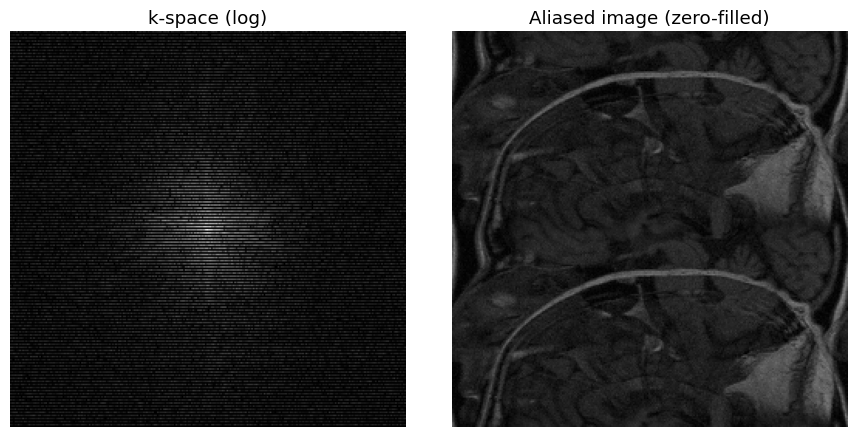

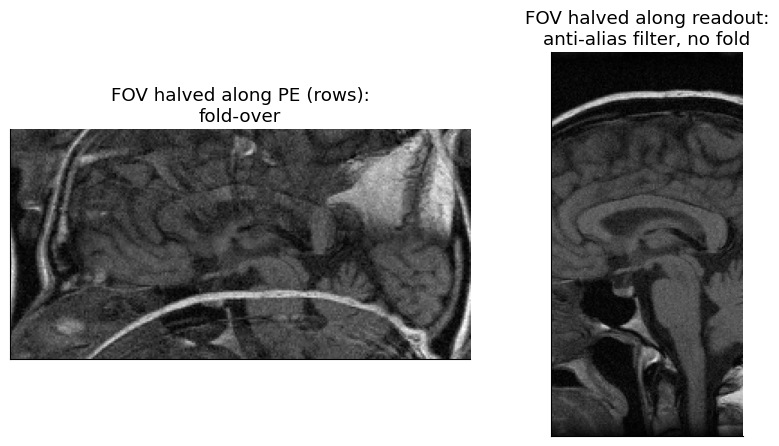

In [4]:
# Aliasing simulation (original): every N_undersamp-th PE line kept, zero-filled to full size
N_undersamp = 2  # >= 1
data_undersamp = np.zeros_like(kdata)
Iundersamp = np.arange(0, S[0], N_undersamp)
data_undersamp[Iundersamp, :] = kdata[Iundersamp, :]
im_undersamp = mt.ifft2c(data_undersamp)
show_pair(data_undersamp, "Aliased image (zero-filled)")
plt.tight_layout(); plt.show()

# Port of generate_image_artifacts.m: a real "FOV too small" scan = fewer lines, smaller matrix
im_smallfov_pe = mt.ifft2c(kdata[::2, :]) * np.sqrt(2)          # FOV_PE halved -> fold-over
# readout direction: analog/digital anti-alias filter = keep only the central half of the image
im_smallfov_fe = im_original[:, S[1] // 4:3 * S[1] // 4]          # FOV_FE halved, no fold
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6))
mt.show_image(im_smallfov_pe, ax=ax[0], vmax=vmax0, title="FOV halved along PE (rows):\nfold-over")
mt.show_image(im_smallfov_fe, ax=ax[1], vmax=vmax0, title="FOV halved along readout:\nanti-alias filter, no fold")
plt.tight_layout(); plt.show()

Zero-filled undersampling gives two overlapping half-intensity copies shifted by $FOV/2$; the real small-FOV scan shows the top and bottom of the head folded into a half-height image. The readout-cropped image simply loses the parts outside the FOV.

**Better / worse:** worse with smaller $FOV_{PE}$, rectangular FOV, large patients, and with surface coils that still see tissue outside the FOV. **Mitigation:** increase $FOV_{PE}$ (costs scan time or resolution), **phase oversampling** ("no phase wrap": acquire a larger FOV and discard the edges — more lines), swap PE and readout so that the long dimension is along readout, spatial saturation bands on tissue outside the FOV, or use only coil elements that do not see the outer tissue. In 3D imaging, aliasing also occurs along the second PE (slice) direction.

### 1.2 Gibbs ringing / truncation

**What you see:** fine parallel lines (ripples) next to sharp, high-contrast edges — e.g. at the skull–brain or CSF–spinal cord interface — decaying with distance from the edge. In the spinal cord this can mimic a syrinx; in the knee, a meniscal tear.

**Cause and math:** The so-called Gibbs ringing or truncation artifact is inherent to Fourier encoding. Sharp edges have infinite extent in k-space. Since only a limited region of k-space can be acquired, i.e. k-space is truncated by a rect window, the image is convolved with the sinc-like PSF ([I1, Section 2](I1_Point_Spread_Function_Analysis.ipynb)):

$$\hat m(x)=m(x)*\left[N\,\mathrm{sinc}(x/\Delta x)\right]$$

In words: the sharp edge becomes slightly blurred and also gets ripples on both sides, at the period of about two pixels (the sidelobe spacing of the sinc).
Where: $\Delta x$ = pixel size [m]. The maximum overshoot next to a step is about **9 %** of the step height (the Gibbs phenomenon) and *does not decrease* with more samples — only the ripples get narrower and closer to the edge.

To alleviate this artifact, the k-space data can be weighted with a so-called **windowing function**, which applies a filter in image space. These windows smoothly decay at the edge of k-space, reducing the ringing, but also lead to a slight loss in spatial resolution (Hamming: FWHM 1.84 instead of 1.21 pixels, see [I1, Section 7](I1_Point_Spread_Function_Analysis.ipynb)).

The next cell is the original simulation (a square object, then a 2D Hann window, then a higher resolution).

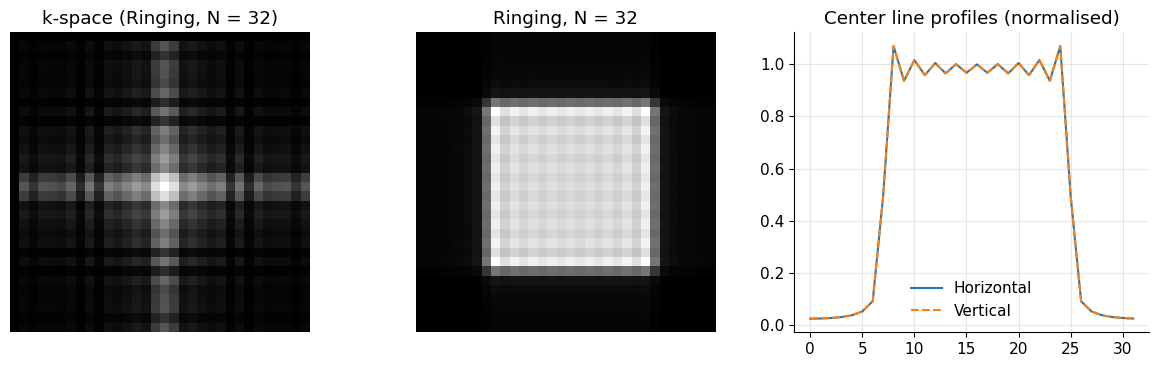

Ringing, N = 32: maximum overshoot = 7.1 % of the plateau


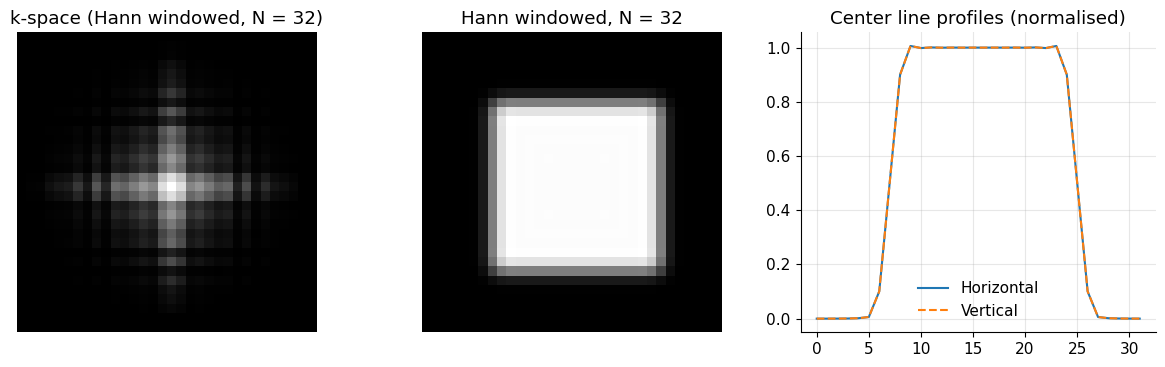

Hann windowed, N = 32: maximum overshoot = 0.6 % of the plateau


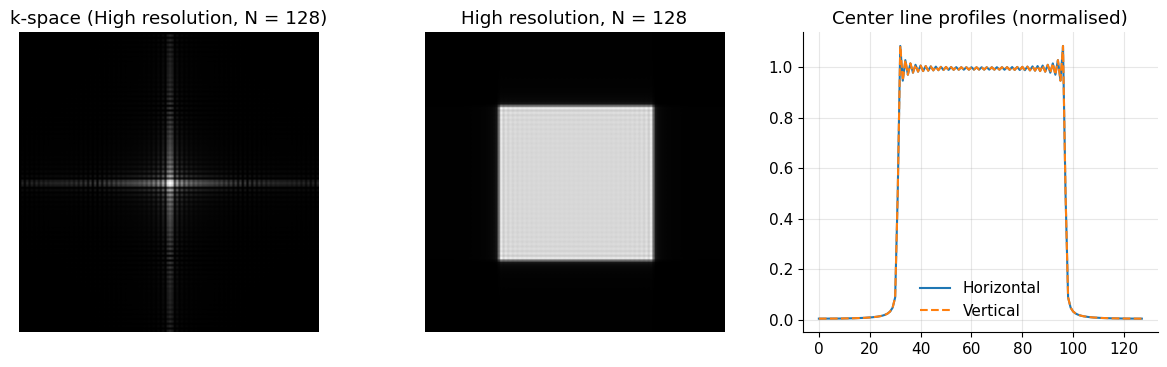

High resolution, N = 128: maximum overshoot = 8.4 % of the plateau


In [5]:
def gibbs_demo(N, window=False, title=""):
    kx = np.arange(-N / 2, N / 2) / N
    N_rect = N // 2 + 2
    K = np.outer(np.sinc(kx * N_rect), np.sinc(kx * N_rect))      # analytic k-space of a square of N_rect pixels
    if window:
        K = K * np.outer(np.hanning(N), np.hanning(N))              # 2D Hann window
    img = mt.ifft2c(K)
    center = N // 2
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
    ax[0].imshow(np.log(np.abs(K) + 1e-2), cmap="gray"); ax[0].axis("off"); ax[0].set_title(f"k-space ({title})")
    ax[1].imshow(np.abs(img), vmin=0, vmax=np.abs(img).max(), cmap="gray"); ax[1].axis("off"); ax[1].set_title(title)
    ax[2].plot(np.abs(img[center, :]) / np.abs(img[center, center]), label="Horizontal")
    ax[2].plot(np.abs(img[:, center]) / np.abs(img[center, center]), "--", label="Vertical")
    ax[2].set_title("Center line profiles (normalised)"); ax[2].legend()
    plt.tight_layout(); plt.show()
    prof = np.abs(img[center, :]) / np.abs(img[center, center])
    print(f"{title}: maximum overshoot = {100 * (prof.max() - 1):.1f} % of the plateau")

gibbs_demo(32, title="Ringing, N = 32")
gibbs_demo(32, window=True, title="Hann windowed, N = 32")
gibbs_demo(128, title="High resolution, N = 128")

Without a window the profile overshoots by roughly 9–13 % (9 % in the continuous limit; the exact discrete value depends on where the edge falls relative to the pixel grid) and ripples. The Hann window removes the ripples but softens the edges. Increasing $N$ from 32 to 128 does not reduce the overshoot, but the ripples become 4× narrower — they occupy a much smaller part of the object.

Now the same on the brain data: keep only the central 64 of the 256 phase-encoding lines (as a low-resolution scan would), with and without a Hamming window along PE.

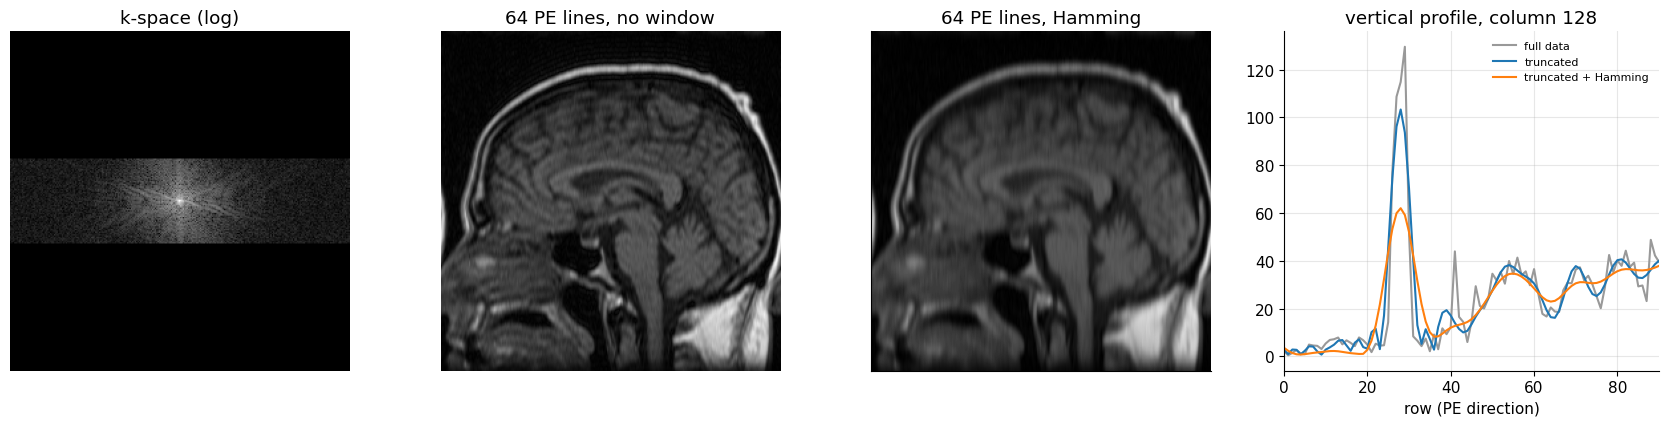

In [6]:
n_keep = 64
K_trunc = np.zeros_like(kdata)
c0 = S[0] // 2
K_trunc[c0 - n_keep // 2:c0 + n_keep // 2, :] = kdata[c0 - n_keep // 2:c0 + n_keep // 2, :]
win_pe = np.zeros(S[0]); win_pe[c0 - n_keep // 2:c0 + n_keep // 2] = np.hamming(n_keep)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
show_pair(K_trunc, f"{n_keep} PE lines, no window", axes=ax[:2])
mt.show_image(mt.ifft2c(K_trunc * win_pe[:, None]), ax=ax[2], vmax=vmax0, title=f"{n_keep} PE lines, Hamming")
col = 128
ax[3].plot(np.abs(im_original[:, col]), color="0.6", label="full data")
ax[3].plot(np.abs(mt.ifft2c(K_trunc)[:, col]), label="truncated")
ax[3].plot(np.abs(mt.ifft2c(K_trunc * win_pe[:, None])[:, col]), label="truncated + Hamming")
ax[3].set_xlim(0, 90); ax[3].set_xlabel("row (PE direction)"); ax[3].legend(fontsize=8)
ax[3].set_title(f"vertical profile, column {col}")
plt.tight_layout(); plt.show()

The truncated image shows horizontal ripples parallel to the skull and the corpus callosum (ringing only along the truncated PE direction); the Hamming-filtered version is ripple-free but blurrier. The profile shows the oscillations near the scalp edge.

**Better / worse:** worse with low matrix (large pixels) relative to the structures, high-contrast edges (fat–CSF, cord–CSF), asymmetric truncation (partial Fourier, partial echo). **Mitigation:** increase the matrix along the affected direction, apply a k-space filter (Hamming, Hann, Tukey…), or use more advanced reconstructions (e.g. sub-voxel-shift Gibbs removal, compressed sensing / deep learning priors).

## 2. Partial volume and boundary artifacts

**What you see:** (a) small structures look faint or blurred; (b) thin **dark lines** along the boundaries between fat and water-based tissue (opposed-phase gradient-echo images, "India ink" artifact) or between tissues in magnitude inversion-recovery images.

**Cause:** The concept of **partial volume** effects refers to an imaging voxel that contains a mixture of materials — different tissues, fat, fluid, or air. This typically occurs at the boundaries of organs or structures, and for anything smaller than a voxel (including through the slice thickness, usually the largest voxel dimension). The voxel signal is the **complex** sum of its contents:

$$s_{voxel}=\sum_{c}f_c\,m_c\,e^{i\phi_c}$$

In words: each compartment $c$ contributes its signal $m_c$ times its volume fraction $f_c$, *with its phase*; if the phases differ, the contributions partly cancel.
Where: $f_c$ = volume fraction of compartment $c$ in the voxel ($\sum f_c=1$); $m_c$ = its signal magnitude; $\phi_c$ = its phase [rad].

The strongest manifestation of this artifact is when the phase of the transverse magnetization, $M_{XY}$, varies between these materials and leads to signal loss within a voxel:

* **Fat–water opposed phase:** fat precesses $\Delta f_{cs}$ slower than water, so at time $TE$ after excitation (gradient echo) the phase difference is $\phi=2\pi\Delta f_{cs}TE$. They are **out of phase** ($\phi=\pi$) at $TE=1/(2|\Delta f_{cs}|)$ ≈ 2.2 ms at 1.5 T and 1.1 ms at 3 T, and **in phase** at multiples of $1/|\Delta f_{cs}|$ ≈ 4.5 ms (1.5 T) and 2.2 ms (3 T). This is the same principle used for [fat/water imaging](D2_In_Vivo_Contrast_Mechanisms.ipynb) (Dixon). To avoid this, in-phase TEs should be chosen.
* **Inversion recovery:** in inversion-recovery sequences the inversion time can make the longitudinal magnetization $M_Z$ positive for some materials and negative for others. A magnitude image of a voxel containing both shows a dark line (the original text ended mid-sentence here).

Below: the in/opposed-phase signal versus TE for a 50/50 fat–water voxel, then a phantom simulated at 4× higher resolution and averaged (complex!) into 4×4 blocks, so boundary voxels really contain mixtures.

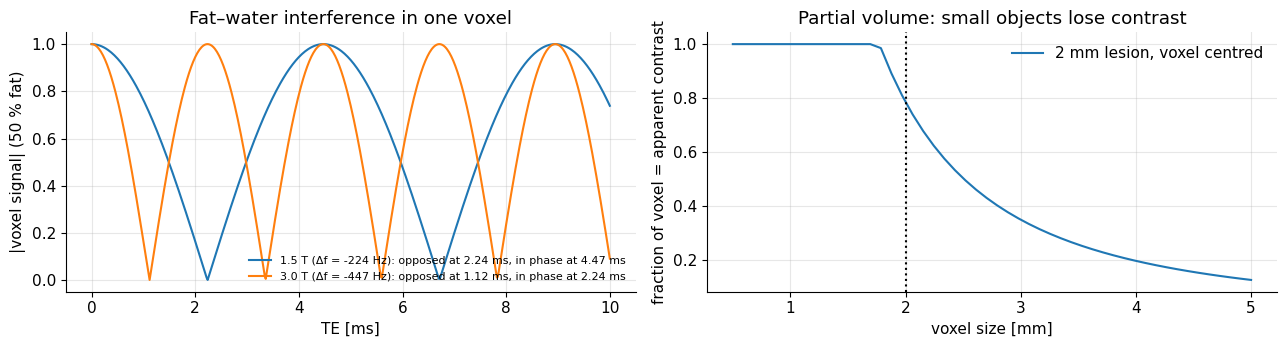

In [7]:
# Signal of a voxel with fat fraction f vs TE (gradient echo, single fat peak, no T2*)
TEs = np.linspace(0, 10e-3, 501)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for B0 in [1.5, 3.0]:
    dfc = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)
    s = np.abs(0.5 + 0.5 * np.exp(-1j * 2 * np.pi * dfc * TEs))
    ax[0].plot(TEs * 1e3, s, label=f"{B0} T (Δf = {dfc:.0f} Hz): opposed at {1e3/(2*abs(dfc)):.2f} ms, "
                                     f"in phase at {1e3/abs(dfc):.2f} ms")
ax[0].set_xlabel("TE [ms]"); ax[0].set_ylabel("|voxel signal| (50 % fat)"); ax[0].legend(fontsize=8)
ax[0].set_title("Fat–water interference in one voxel")

# Partial volume of a small object: signal of a disk vs voxel size
diam = 2.0e-3                                            # lesion diameter 2 mm
vox = np.linspace(0.5e-3, 5e-3, 50)                      # voxel size (in-plane, square) [m]
# fraction of a voxel (centred on the lesion) filled, for a disk: area / voxel area (capped at 1)
frac = np.minimum(1, np.pi * (diam / 2)**2 / vox**2)
ax[1].plot(vox * 1e3, frac, label="2 mm lesion, voxel centred")
ax[1].axvline(diam * 1e3, color="k", ls=":")
ax[1].set_xlabel("voxel size [mm]"); ax[1].set_ylabel("fraction of voxel = apparent contrast")
ax[1].set_title("Partial volume: small objects lose contrast"); ax[1].legend()
plt.tight_layout(); plt.show()

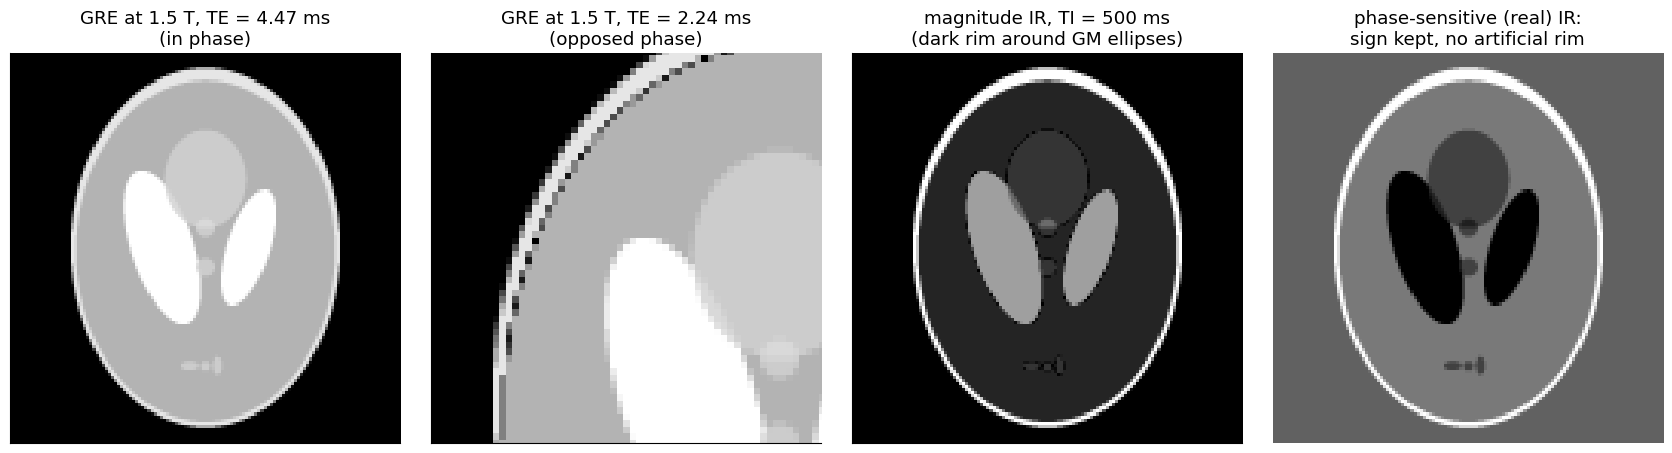

WM: Mz-based IR signal at TI = 500 ms: +0.13
GM: Mz-based IR signal at TI = 500 ms: -0.17


In [8]:
# Phantom at 4x resolution -> complex 4x4 averaging -> boundary voxels contain mixtures
up = 4
Nlo = 128
ph_hr = mt.tissue_phantom(Nlo * up)
lab_hr = ph_hr["labels"]

def block_average(img, f=up):
    n = img.shape[0] // f
    return img.reshape(n, f, n, f).mean(axis=(1, 3))

B0 = 1.5
dfc = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)
fat_hr = (lab_hr == 1) * ph_hr["M0"]
water_hr = (lab_hr > 1) * ph_hr["M0"]

fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
for a_, TE in zip(ax[:2], [1 / abs(dfc), 1 / (2 * abs(dfc))]):
    vox_sig = block_average(water_hr + fat_hr * np.exp(-1j * 2 * np.pi * dfc * TE))
    mt.show_image(vox_sig, ax=a_, vmax=1, title=f"GRE at {B0} T, TE = {TE*1e3:.2f} ms\n"
                                               f"({'in' if a_ is ax[0] else 'opposed'} phase)")
ax[1].set_xlim(10, 70); ax[1].set_ylim(70, 10)
# Inversion recovery boundary: WM (T1 0.6 s) positive, GM (T1 0.95 s) negative at TI = 0.5 s
TI, TR = 0.5, 4.0
sig_hr = mt.inversion_recovery_signal(TI, TR, 0.0, ph_hr["T1"], ph_hr["T2"], ph_hr["M0"]) * (lab_hr > 0)
ir = block_average(sig_hr)
mt.show_image(np.abs(ir), ax=ax[2], title=f"magnitude IR, TI = {TI*1e3:.0f} ms\n(dark rim around GM ellipses)")
ax[3].imshow(np.real(ir), cmap="gray"); ax[3].axis("off")
ax[3].set_title("phase-sensitive (real) IR:\nsign kept, no artificial rim")
plt.tight_layout(); plt.show()
for name, T1 in [("WM", 0.60), ("GM", 0.95)]:
    print(f"{name}: Mz-based IR signal at TI = {TI*1e3:.0f} ms: {mt.inversion_recovery_signal(TI, TR, 0, T1, 0.1):+.2f}")

> **TODO (polish):** the opposed-phase dark line is faint at this display size; zoom/contrast of the panel should be improved (e.g. a profile across the fat–brain boundary).

In phase, the fat ring and the brain simply add at the boundary. Opposed phase (zoomed), a thin **dark line** appears exactly where boundary voxels contain both fat and water — although nothing dark is in the object. In the magnitude IR image, the voxels where positive (WM) and negative (GM) magnetization meet cancel, outlining the grey-matter ellipses with a dark rim; phase-sensitive (real-valued) IR reconstruction keeps the sign and avoids the artificial line.

**Better / worse:** partial volume worsens with larger voxels (especially thick slices); the India-ink line appears at opposed-phase TE, and in IR at TIs between the two tissues' null points. **Mitigation:** smaller voxels / thinner slices; in-phase TE or fat suppression or Dixon; phase-sensitive IR reconstruction or a different TI.

## 3. Displacement and distortion artifacts due to changes in frequency

Since MRI relies on frequency to encode spatial information, unknown frequency shifts lead to distortions of the image. These frequency shifts are due to chemical shift (e.g. fat) and/or off-resonance (e.g. main field inhomogeneities, susceptibility differences).

### 3.1 Shifts in the image

From the PSF analysis ([I1, Section 6](I1_Point_Spread_Function_Analysis.ipynb)), a frequency offset $\Delta f$ causes a shift during frequency encoding of

$$\Delta_{FE} = \frac{\Delta f}{BW_{read}}\, FOV_{FE}$$

In words: the displacement is the frequency offset as a fraction of the total receiver bandwidth, times the FOV — equivalently $\Delta f/BW_{pix}$ pixels.
Where: $\Delta f$ = frequency shift [Hz]; $BW_{read}$ = receiver bandwidth [Hz] (the original's $RBW$); $FOV_{FE}$ = field of view in the frequency-encoding direction [m].

During EPI, there is typically a much larger shift in the phase-encoding direction that depends on how much phase accumulates across k-space. This depends on the echo spacing, $t_{esp}$, as well as how many k-space lines are covered in adjacent echoes, defined here as $N_{steps}$. To characterize this, we define a "phase-encoding bandwidth", $BW_{PE} = N_{steps}/t_{esp}$, and the displacement is

$$\Delta_{PE,EPI} = \frac{\Delta f}{BW_{PE}}\, FOV_{PE}$$

In words: the same formula, with the (much smaller) rate at which EPI moves through $k_y$.
Where: $t_{esp}$ [s] = time between consecutive echoes; $N_{steps}$ = number of k-space lines advanced per echo; $FOV_{PE}$ [m].

$N_{steps}$ depends on whether there is any interleaving, and whether parallel imaging is used to skip lines. For example, EPI without acceleration in a single shot has $N_{steps} = 1$, 2 interleaves have $N_{steps} = 2$, single-shot with $R=2$ parallel imaging acceleration has $N_{steps} = 2$, and 2 interleaves with $R=2$ parallel imaging have $N_{steps} = 4$.

In [9]:
# Displacements for typical protocols
def disp_mm(df, BW, FOV):
    return df / BW * FOV * 1e3

for B0 in [1.5, 3.0]:
    dfat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)
    print(f"--- B0 = {B0} T, fat offset {dfat:.0f} Hz ---")
    print(f"  2DFT, BW_read = 32 kHz, FOV = 24 cm, N = 256: {disp_mm(dfat, 32e3, 0.24):6.2f} mm "
          f"= {dfat / (32e3 / 256):5.2f} pixels")
    for Nsteps, lab in [(1, "single shot"), (2, "R = 2 or 2 interleaves"), (4, "R = 2 and 2 interleaves")]:
        BWpe = Nsteps / 0.5e-3
        print(f"  EPI tesp = 0.5 ms, {lab:24s}: BW_PE = {BWpe/1e3:.0f} kHz -> {disp_mm(dfat, BWpe, 0.24):6.1f} mm "
              f"= {dfat / BWpe * 96:5.1f} pixels (N_PE = 96)")

--- B0 = 1.5 T, fat offset -224 Hz ---
  2DFT, BW_read = 32 kHz, FOV = 24 cm, N = 256:  -1.68 mm = -1.79 pixels
  EPI tesp = 0.5 ms, single shot             : BW_PE = 2 kHz ->  -26.8 mm = -10.7 pixels (N_PE = 96)
  EPI tesp = 0.5 ms, R = 2 or 2 interleaves  : BW_PE = 4 kHz ->  -13.4 mm =  -5.4 pixels (N_PE = 96)
  EPI tesp = 0.5 ms, R = 2 and 2 interleaves : BW_PE = 8 kHz ->   -6.7 mm =  -2.7 pixels (N_PE = 96)
--- B0 = 3.0 T, fat offset -447 Hz ---
  2DFT, BW_read = 32 kHz, FOV = 24 cm, N = 256:  -3.35 mm = -3.58 pixels
  EPI tesp = 0.5 ms, single shot             : BW_PE = 2 kHz ->  -53.6 mm = -21.5 pixels (N_PE = 96)
  EPI tesp = 0.5 ms, R = 2 or 2 interleaves  : BW_PE = 4 kHz ->  -26.8 mm = -10.7 pixels (N_PE = 96)
  EPI tesp = 0.5 ms, R = 2 and 2 interleaves : BW_PE = 8 kHz ->  -13.4 mm =  -5.4 pixels (N_PE = 96)


### 3.2 Fat chemical shift artifact — displacement

**What you see:** fat-containing structures (subcutaneous fat, bone marrow, orbital fat, scalp lipids) are shifted relative to the water-based tissue: a dark gap on one side and a bright overlap band on the other side of fat–water boundaries, along the readout direction in 2DFT and along PE in EPI.

**Cause and math:** there is a constant frequency difference between fat and water ($\approx-3.5$ ppm, −224 Hz at 1.5 T, −447 Hz at 3 T). This leads to a **constant displacement** of the fat signal relative to the water signal, $\hat m=m_{water}+m_{fat}(x-\Delta_{FE})$.

![Axial brain EPI with fat displacement](../images/artifacts/epi_fat_artifact.jpg)

*Axial brain EPI image showing a fat displacement artifact (arrows) of the lipids in the skull.*

The simulation decomposes the phantom into water and fat ("scalp" ring) and applies the fat phase $e^{-i2\pi\Delta f_{fat}\upsilon(\vec k)}$ in k-space — readout direction for 2DFT, PE direction for EPI.

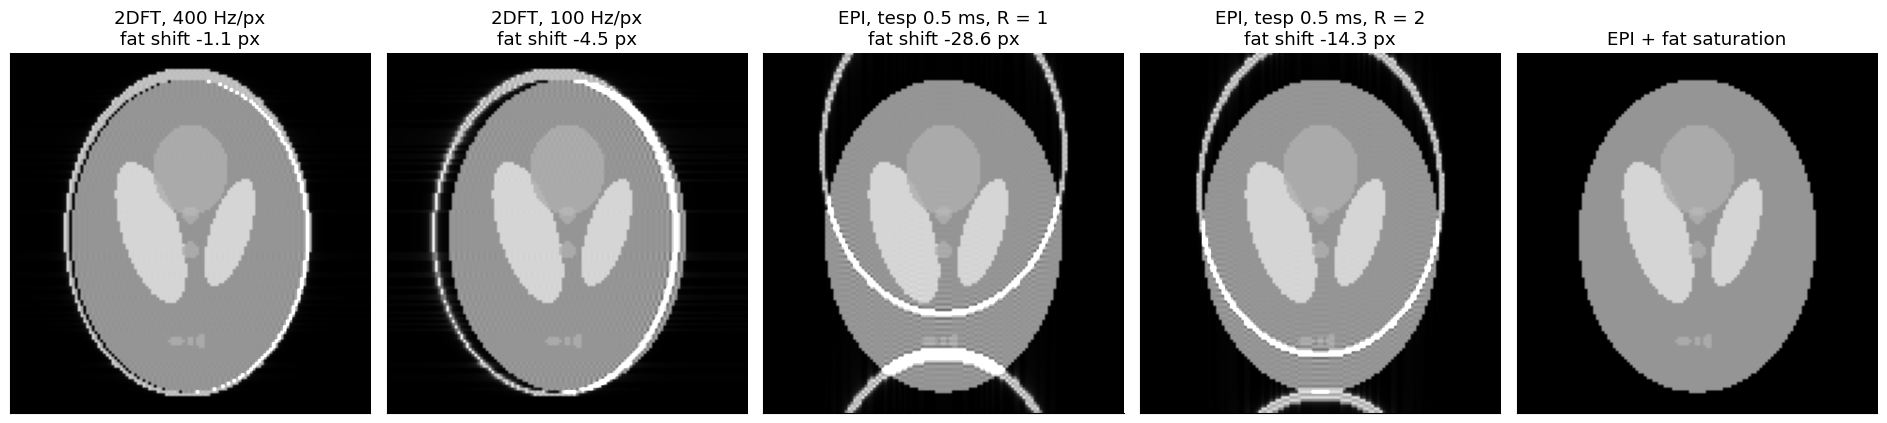

In [10]:
Nim = 128
ph = mt.tissue_phantom(Nim)
m_water = ph["M0"] * (ph["labels"] > 1)
m_fat = ph["M0"] * (ph["labels"] == 1)
pidx = np.arange(Nim) - Nim // 2
KX, KY = np.meshgrid(pidx, pidx)          # sample index; columns = kx (readout), rows = ky (PE)
dfat3 = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)

def water_fat(time_map):
    return mt.ifft2c(mt.fft2c(m_water) + mt.fft2c(m_fat) * np.exp(-1j * 2 * np.pi * dfat3 * time_map))

cases = [("2DFT, 400 Hz/px", KX / (Nim * 400.0)), ("2DFT, 100 Hz/px", KX / (Nim * 100.0)),
         ("EPI, tesp 0.5 ms, R = 1", KY * 0.5e-3), ("EPI, tesp 0.5 ms, R = 2", KY * 0.5e-3 / 2),
         ("EPI + fat saturation", None)]
fig, ax = plt.subplots(1, 5, figsize=(19, 4.2))
for a_, (name, tm) in zip(ax, cases):
    img = mt.ifft2c(mt.fft2c(m_water)) if tm is None else water_fat(tm)
    shift = "" if tm is None else f"\nfat shift {dfat3 * (tm.max() - tm.min()) * Nim / (Nim - 1):.1f} px"
    mt.show_image(img, ax=a_, vmax=1.2, title=name + shift)
plt.tight_layout(); plt.show()

A higher bandwidth per pixel shrinks the 2DFT shift; parallel imaging ($R=2$, i.e. $N_{steps}=2$) halves the EPI shift; fat saturation removes it.

**Better / worse:** worse at higher $B_0$ (Δf ∝ $B_0$), lower bandwidth, larger matrix at fixed bandwidth, and dramatically in EPI. **Mitigation:** increase $BW_{read}$ (costs SNR, $\propto1/\sqrt{BW}$), fat suppression (spectral saturation, STIR, water excitation), Dixon fat/water imaging, swap PE/FE so that the shift is in a harmless direction, parallel imaging / segmentation for EPI.

### 3.3 Off-resonance artifacts — distortion

**What you see:** geometric **stretching and compression** of anatomy near air–tissue interfaces (frontal sinus, ear canals, bowel gas, lung) or metal implants; regions that are compressed look bright ("pile-up"), stretched regions dark. In EPI, the frontal lobes and temporal lobes bend along PE.

**Cause and math:** Off-resonance, which most significantly arises from differences in magnetic susceptibility $\chi$ between materials, is smoothly varying and increases at the boundaries between them. This leads to *variable* shifts in the image, largest at these boundaries — a **distortion**, not a uniform shift. Locally, each point is displaced by

$$\Delta y(\vec r)=\frac{\Delta f_r(\vec r)}{BW_{PE}}FOV_{PE}\quad\text{(EPI)},\qquad\Delta x(\vec r)=\frac{\Delta f_r(\vec r)}{BW_{read}}FOV_{FE}\quad\text{(2DFT)}$$

In words: the I1 shift formula applied point by point with the local off-resonance.
Where: $\Delta f_r(\vec r)=\bar\gamma\,\Delta B_0(\vec r)$ [Hz].

Because the shift varies across the object, intensities also change: where neighbouring points are pushed together the signal piles up (bright), where they are pulled apart it thins out (dark) — the intensity changes by the Jacobian $1/|1+\partial\Delta y/\partial y|$.

**Where does $\Delta B_0$ come from?** A material with susceptibility $\chi$ becomes slightly magnetized in $B_0$ and adds its own small field. For a sphere of radius $a$ with susceptibility difference $\Delta\chi$ relative to its surroundings, the extra field outside is a dipole field:

$$\Delta B_z(r,\vartheta)=\frac{\Delta\chi}{3}B_0\,\frac{a^3}{r^3}\left(3\cos^2\vartheta-1\right)\qquad(r>a)$$

In words: the disturbance is largest at the sphere's surface, positive along the $B_0$ axis and negative around its "equator", and falls off as $1/r^3$.
Where: $r$ = distance from the sphere centre [m]; $\vartheta$ = angle between $\vec r$ and $\vec B_0$ (written $\vartheta$ to avoid a clash with the flip angle $\theta$); $\Delta\chi=\chi_{air}-\chi_{tissue}\approx0.36\times10^{-6}-(-9.05\times10^{-6})\approx9.4\times10^{-6}$. At 3 T the field at the poles of an air cavity reaches $\frac{2}{3}\Delta\chi\,\bar\gamma B_0\approx800$ Hz.

![Axial brain EPI with distortion](../images/artifacts/epi_distortion_artifact_changes.jpg)

*Axial brain EPI images showing distortion artifacts (arrows) near the frontal sinus where there are air–tissue interfaces. The right image used a reduced echo spacing, leading to increased phase-encoding bandwidth that reduces the severity of this artifact.*

**Simulation (explicit forward model).** A spatially varying $\Delta f$ is not a convolution, so we simulate the signal equation directly. Because in EPI all samples of one $k_y$ line are acquired within a fraction of a ms, we assume each line $j$ is acquired at a single time $t_j=TE+(j-N/2)\,t_{esp}/N_{steps}$; then

$$\hat M(k_x,k_{y,j})=\mathcal F\left\{m(\vec r)\,e^{-i2\pi\Delta f(\vec r)\,\tau_j}\right\}(k_x,k_{y,j})$$

In words: for each k-space line, Fourier transform the object *as it looks at that line's time* (with the off-resonance phase it has accumulated) and keep only that line.
Where: $\tau_j=t_j$ for a gradient echo (phase accumulates from the excitation), $\tau_j=t_j-TE$ for a spin echo (the 180° pulse refocuses the phase at $TE$).

To capture **signal loss** from dephasing *within* a voxel as well, we compute the object on a 4× finer grid and average the complex signal into each voxel (like the partial-volume demo above). The air cavity is a sphere (centred in this slice) in the frontal part of the phantom, with $B_0$ pointing along the image vertical.

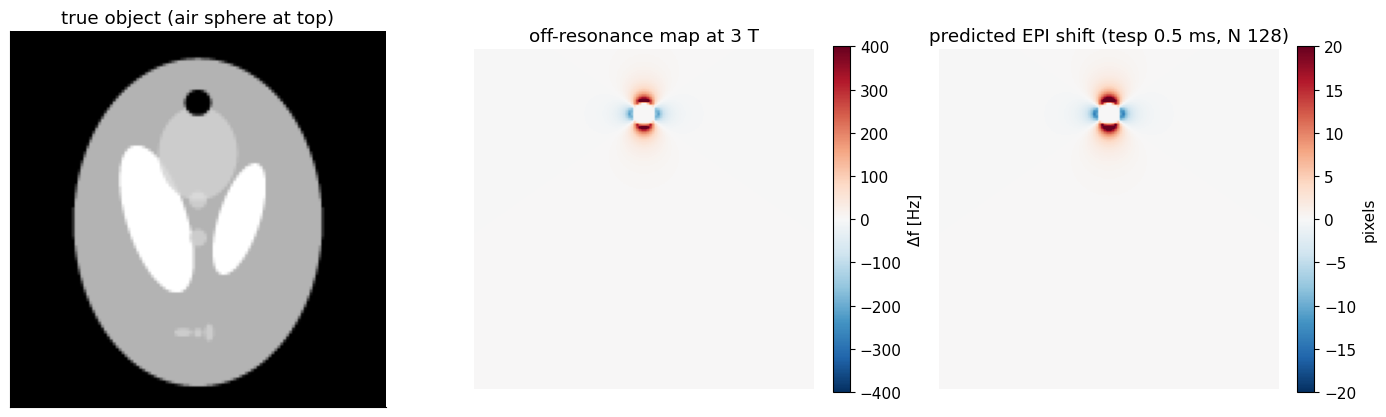

max |Δf| = 795 Hz; EPI BW/pixel along PE = 15.6 Hz


In [11]:
# High-resolution phantom with an air-filled sphere ("frontal sinus") and its susceptibility field
up, Nlo = 4, 128
Nhr = Nlo * up
FOVm = 0.24                                                  # [m]
ph_hr = mt.tissue_phantom(Nhr)
yy, xx = np.mgrid[1:-1:Nhr * 1j, -1:1:Nhr * 1j]              # same normalized coordinates as the phantom
a_s, yc_s = 0.07, 0.62                                        # sphere radius and centre (normalized units)
xm, ym = xx * FOVm / 2, (yy - yc_s) * FOVm / 2                # [m], relative to the sphere centre
r = np.sqrt(xm**2 + ym**2)
cos2 = np.where(r > 0, ym**2 / np.maximum(r, 1e-12)**2, 1.0)   # B0 along image vertical (y)
a_m = a_s * FOVm / 2
B0 = 3.0
dchi = 9.4e-6
dB = np.where(r > a_m, dchi / 3 * B0 * (a_m / np.maximum(r, a_m))**3 * (3 * cos2 - 1), 0.0)
df_hr = mt.GAMMA_BAR * dB                                     # off-resonance [Hz]
m_hr = ph_hr["M0"] * (ph_hr["labels"] > 1) * (r > a_m)       # brain only (no fat ring, avoids mixing effects); air = 0

def epi_forward(m_hr, df_hr, tesp=0.5e-3, Nsteps=1, spin_echo=False, TE=30e-3, pe_sign=+1):
    """Simulate a (single-shot) EPI acquisition line by line. Rows = PE (ky)."""
    K = np.zeros((Nlo, Nlo), complex)
    for j in range(Nlo):
        t_j = TE + pe_sign * (j - Nlo // 2) * tesp / Nsteps
        tau = t_j - TE if spin_echo else t_j
        obj = block_average(m_hr * np.exp(-1j * 2 * np.pi * df_hr * tau))
        K[j, :] = mt.fft2c(obj)[j, :]
    return mt.ifft2c(K)

def cart_forward(m_hr, df_hr, BWpix=200.0, spin_echo=True, TE=15e-3):
    """Simulate a 2DFT acquisition column by column (time varies along kx = columns)."""
    K = np.zeros((Nlo, Nlo), complex)
    for c in range(Nlo):
        t_c = TE + (c - Nlo // 2) / (Nlo * BWpix)
        tau = t_c - TE if spin_echo else t_c
        obj = block_average(m_hr * np.exp(-1j * 2 * np.pi * df_hr * tau))
        K[:, c] = mt.fft2c(obj)[:, c]
    return mt.ifft2c(K)

df_lo = block_average(df_hr)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
mt.show_image(block_average(m_hr), ax=ax[0], title="true object (air sphere at top)")
im_ = ax[1].imshow(df_lo, cmap="RdBu_r", vmin=-400, vmax=400); ax[1].axis("off")
plt.colorbar(im_, ax=ax[1], fraction=0.046, label="Δf [Hz]"); ax[1].set_title("off-resonance map at 3 T")
im_ = ax[2].imshow(df_lo * Nlo * 0.5e-3, cmap="RdBu_r", vmin=-20, vmax=20); ax[2].axis("off")
plt.colorbar(im_, ax=ax[2], fraction=0.046, label="pixels"); ax[2].set_title("predicted EPI shift (tesp 0.5 ms, N 128)")
plt.tight_layout(); plt.show()
print(f"max |Δf| = {np.abs(df_hr).max():.0f} Hz; EPI BW/pixel along PE = {1/(Nlo*0.5e-3):.1f} Hz")

The dipole pattern is clearly visible: positive off-resonance above and below the cavity (along $B_0$), negative at its sides. With an EPI bandwidth of 15.6 Hz/pixel along PE, a few hundred Hz means shifts of tens of pixels near the cavity. Now the images:

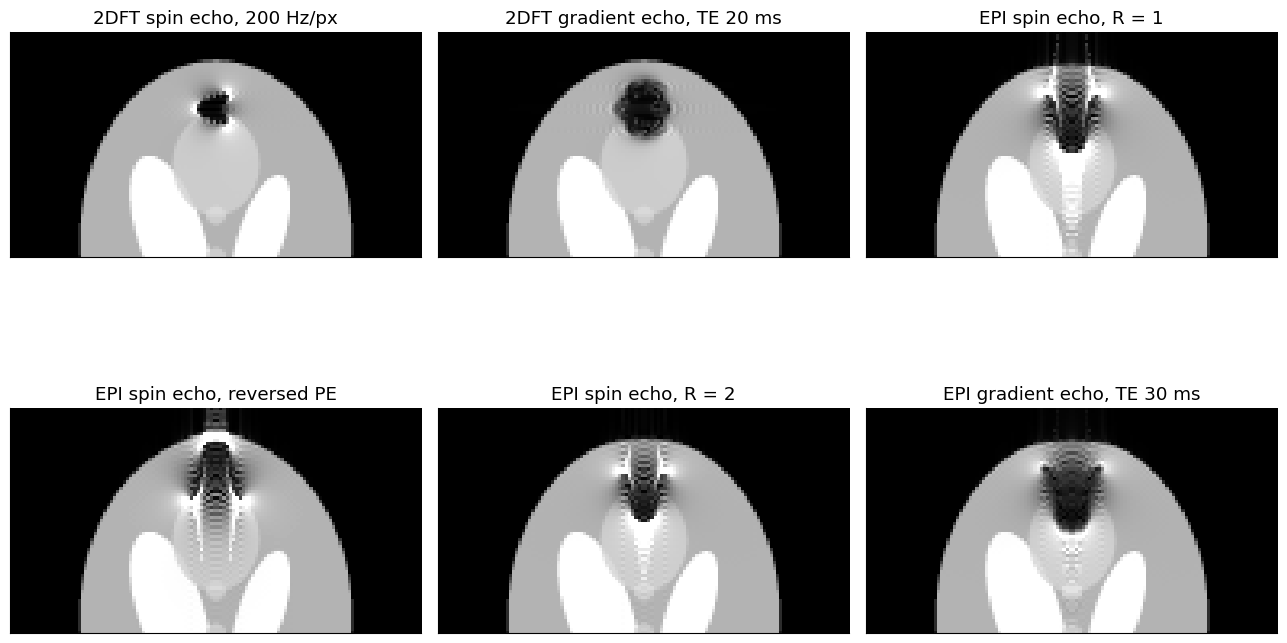

In [12]:
sims = [
    ("2DFT spin echo, 200 Hz/px", cart_forward(m_hr, df_hr, 200.0, spin_echo=True)),
    ("2DFT gradient echo, TE 20 ms", cart_forward(m_hr, df_hr, 200.0, spin_echo=False, TE=20e-3)),
    ("EPI spin echo, R = 1", epi_forward(m_hr, df_hr, spin_echo=True)),
    ("EPI spin echo, reversed PE", epi_forward(m_hr, df_hr, spin_echo=True, pe_sign=-1)),
    ("EPI spin echo, R = 2", epi_forward(m_hr, df_hr, spin_echo=True, Nsteps=2)),
    ("EPI gradient echo, TE 30 ms", epi_forward(m_hr, df_hr, spin_echo=False, TE=30e-3)),
]
fig, ax = plt.subplots(2, 3, figsize=(13, 9))
for a_, (name, img) in zip(ax.ravel(), sims):
    mt.show_image(img, ax=a_, vmax=1.0, title=name)
    a_.set_ylim(70, 0)                                        # zoom on the upper half (around the cavity)
plt.tight_layout(); plt.show()

* **2DFT spin echo** (200 Hz/pixel): the cavity is almost undistorted (shifts ≤ 2 pixels along the horizontal readout).
* **2DFT gradient echo, TE = 20 ms:** geometry is fine but **signal voids** appear around the cavity: within one voxel the off-resonance varies by tens of Hz, so after 20 ms the spins inside the voxel point in different directions and cancel ("$T_2^*$ artifact", next section).
* **EPI spin echo:** strong **distortion along PE** (vertical): tissue above/below the cavity is pushed one way and piles up (bright), regions are stretched (dark).
* **Reversed PE direction:** the distortion flips — the basis of "blip-up/blip-down" distortion correction (e.g. FSL *topup*), which estimates the field from two such images.
* **EPI with R = 2:** half the shift (twice the effective PE bandwidth).
* **EPI gradient echo (fMRI-like):** distortion *and* signal void.

**Better / worse:** worse at higher $B_0$ (Δf ∝ $B_0$), near air/bone/metal, with low $BW_{pix}$ (EPI, long $t_{esp}$, large $N_{PE}$), poor shim. **Mitigation:** shimming (including higher-order and slice-specific dynamic shimming), higher bandwidth, shorter $t_{esp}$, parallel imaging or segmented/multi-shot EPI, readout-segmented EPI, swapping PE direction, field-map or reversed-PE based distortion correction; for metal: view-angle tilting, SEMAC/MAVRIC.

> **🔧 Engineering reality:** The EPI echo spacing is limited by gradient amplitude and slew rate (a 0.5 ms echo spacing at 2 mm resolution needs ≈ 30 mT/m readout plateaus switched at > 150 T/m/s) and by **peripheral nerve stimulation**, which caps $dB/dt$ regardless of hardware ([Gradient System Engineering](B4_Gradient_System_Engineering.ipynb), [MRI Safety](B6_MRI_Safety.ipynb)). This is why distortion in EPI cannot simply be engineered away by stronger gradients.

### 3.4 Shifts in slice selection

Finally, there is also a displacement of the excited slice:

$$\Delta_{SS} = \frac{\Delta f}{BW_{rf}}\, \Delta z$$

In words: a frequency offset moves the slice by the same fraction of the slice thickness as the offset is a fraction of the RF bandwidth ([Slice Selection](E2_Slice_Selection.ipynb)).
Where: $BW_{rf}$ = bandwidth of the slice-selective RF pulse [Hz]; $\Delta z$ = slice thickness [m].

This effect is not as obvious in images, but important to be aware of in pulse sequence design. Example at 3 T: fat (−447 Hz), $BW_{rf}$ = 1 kHz, $\Delta z$ = 5 mm → $\Delta_{SS}$ ≈ 2.2 mm — the fat "slice" is offset by almost half a slice thickness. Off-resonant regions near implants can have their slice bent into a "potato chip" shape. **Mitigation:** higher RF bandwidth (shorter or higher-TBW pulses: more SAR, more peak $B_1$), shimming, 3D imaging (no slice selection), fat suppression; SEMAC for metal.

In [13]:
for B0 in [1.5, 3.0, 7.0]:
    dfat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)
    print(f"B0 = {B0} T: fat slice shift for BW_rf = 1 kHz, dz = 5 mm: {dfat / 1e3 * 5:5.2f} mm;"
          f"  with BW_rf = 3 kHz: {dfat / 3e3 * 5:5.2f} mm")

B0 = 1.5 T: fat slice shift for BW_rf = 1 kHz, dz = 5 mm: -1.12 mm;  with BW_rf = 3 kHz: -0.37 mm
B0 = 3.0 T: fat slice shift for BW_rf = 1 kHz, dz = 5 mm: -2.24 mm;  with BW_rf = 3 kHz: -0.75 mm
B0 = 7.0 T: fat slice shift for BW_rf = 1 kHz, dz = 5 mm: -5.22 mm;  with BW_rf = 3 kHz: -1.74 mm


### 3.5 $T_2^*$ signal loss (susceptibility voids)

$T_2^*$ can be a source of artifact and contrast. Macroscopic, inter-voxel effects, such as those arising at boundaries between materials with different magnetic susceptibilities, lead to shorter $T_2^*$ and are typically considered an artifact. The mechanism (seen in the simulation above): within one voxel the frequency varies by $\delta f$, so at the echo time the voxel signal is reduced by roughly $|\mathrm{sinc}(\delta f\,TE)|$ (uniform frequency spread across the voxel). This can be removed by using spin-echo sequences (the 180° pulse refocuses static off-resonance at $TE$).

![Axial brain image with T2* artifact](../images/artifacts/epi_T2star_artifact.png)

*Axial brain EPI image showing a $T_2^*$ artifact (arrows) in the frontal lobe, which is due to magnetic susceptibility differences between the air in the frontal sinuses and the brain tissue.*

**Better / worse:** worse with long TE, large voxels (especially thick slices: through-slice field gradients dominate in practice), high $B_0$, gradient echo. **Mitigation:** spin echo, shorter TE, thinner slices, shimming, z-shimming (compensation gradient through the slice), ultrashort-TE sequences near metal.

## 4. Motion and flow artifacts

Motion, including flow, results in artifacts if it leads to **inconsistency** between the k-space data acquired at different times.

**Math:** suppose the object is rigidly translated by $d_j$ (along $y$) while PE line $j$ is acquired. By the shift theorem, line $j$ gets a phase factor:

$$\hat M(k_x,k_{y,j})=M(k_x,k_{y,j})\,e^{-i2\pi k_{y,j}d_j}$$

In words: motion is a k-space weighting that changes **from line to line** — a pattern along $k_y$ — and therefore produces artifacts along the **phase-encoding** direction (even if the motion itself is along the readout direction: then the phase factor is $e^{-i2\pi k_xd_j}$, still different for each line $j$).
Where: $k_{y,j}$ [m⁻¹] = the PE value of line $j$; $d_j$ [m] = displacement at that time. Within one line (a few ms) nothing moves noticeably, so the readout direction is clean.

### 4.1 Periodic motion — ghosting

Periodic motion such as breathing, heart beating and pulsatile flow leads to distinct ghosting artifacts in the phase-encoding direction. If the line-to-line modulation has period $P=T_{motion}/TR$ lines, then (by the modulation/shift property of the DFT) the image gets copies shifted by multiples of $N_{PE}/P$ pixels. The location of ghosting artifacts in sequential phase encoding without parallel imaging is therefore at predictable intervals:

$$\Delta_{PE} = \frac{TR}{T_{motion}}\, FOV_{PE}$$

In words: ghosts repeat every $TR/T_{motion}$ of the FOV (wrapping around if larger than the FOV).
Where: $T_{motion}$ = period of the motion (e.g. $T_{motion} = 1$ s for a heart rate of 60 beats per minute, ≈ 4 s for breathing); $TR$ = time between consecutive PE lines [s]; $FOV_{PE}$ [m].

<details><summary><b>📐 Derivation (optional): ghost positions and amplitudes</b></summary>

Write the line-dependent weighting as a periodic function of the line index, $W_j=g(j)$ with $g(j+P)=g(j)$. Expand it as a Fourier series: $g(j)=\sum_q c_q\,e^{i2\pi qj/P}$. Multiplying k-space line $j$ by $e^{i2\pi qj/P}$ shifts the image by $qN_{PE}/P$ pixels (modulation theorem, the dual of the shift theorem). So

$$\hat m(x,y)=\sum_q c_q\,m\!\left(x,\;y-q\tfrac{N_{PE}}{P}\Delta y\right)$$

— the true image ($q=0$, weight $c_0$) plus ghosts at multiples of $N_{PE}/P=N_{PE}TR/T_{motion}$ pixels with weights $c_q$. For a small sinusoidal amplitude modulation $g=1+\epsilon\cos(2\pi j/P)$ there are exactly two ghosts with amplitude $\epsilon/2$. For translation, $g$ also depends on $k_y$ (the phase $2\pi k_yd_j$ grows toward the k-space edge), so the ghosts are edge-enhanced copies — the edges of moving structures ghost most strongly.

</details>

![Axial abdomen image with motion](../images/artifacts/abdomen_motion.png)

*Axial abdomen image with artifacts from respiratory motion in the phase-encoding direction. There are multiple distinct ghosts of the anterior abdominal wall, which is what is moving during breathing.*

**Simulation:** we apply per-line phase errors to the real k-space data: (a) the whole head moving sinusoidally along PE, (b) only the upper part of the image moving (like the abdominal wall), using the linearity/decomposition principle, (c) motion along the *readout* direction, (d) random motion.

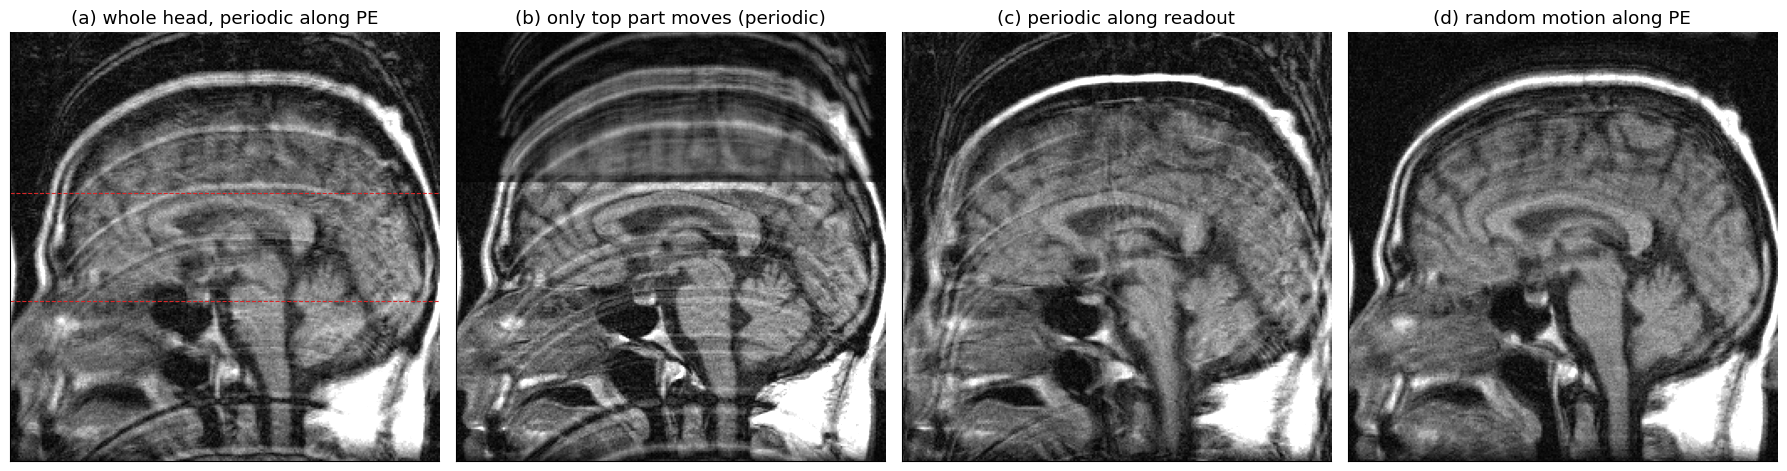

predicted ghost spacing = N_PE * TR / T_motion = 32 pixels (dashed red lines: centre ± one spacing)


In [14]:
TR = 0.5                                  # [s], time between PE lines (spin-echo T1w-like)
N_PE = S[0]
j = np.arange(N_PE)
ky = (j - N_PE // 2) / N_PE               # ky in cycles/pixel (i.e. k * pixel size)
kx = (np.arange(S[1]) - S[1] // 2) / S[1]
T_motion = 4.0                            # breathing period [s]
amp_px = 3.0                              # motion amplitude [pixels]
d = amp_px * np.sin(2 * np.pi * j * TR / T_motion)        # displacement per line [pixels]

rng = np.random.default_rng(1)
d_random = np.cumsum(rng.standard_normal(N_PE)) * 0.4     # random walk (drift + jitter) [pixels]
d_random -= d_random.mean()

def move_pe(K, d):      # translation along PE (rows) by d[j] pixels during line j
    return K * np.exp(-1j * 2 * np.pi * ky[:, None] * d[:, None])

def move_fe(K, d):      # translation along readout (columns) by d[j] pixels during line j
    return K * np.exp(-1j * 2 * np.pi * kx[None, :] * d[:, None])

# (b) only the top part moves: split the image into two components and move one
mask_top = np.zeros(S); mask_top[:90, :] = 1
K_top, K_rest = mt.fft2c(im_original * mask_top), mt.fft2c(im_original * (1 - mask_top))

results = [("(a) whole head, periodic along PE", move_pe(kdata, d)),
           ("(b) only top part moves (periodic)", move_pe(K_top, 2 * d) + K_rest),
           ("(c) periodic along readout", move_fe(kdata, d)),
           ("(d) random motion along PE", move_pe(kdata, d_random))]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
for a_, (name, K) in zip(ax, results):
    mt.show_image(mt.ifft2c(K), ax=a_, vmax=0.6 * vmax0, title=name)
spacing = N_PE * TR / T_motion
for q in [-1, 1]:
    ax[0].axhline(S[0] // 2 + q * spacing, color="C3", lw=0.8, ls="--")
plt.tight_layout(); plt.show()
print(f"predicted ghost spacing = N_PE * TR / T_motion = {spacing:.0f} pixels (dashed red lines: centre ± one spacing)")

(The display window is narrowed to 60 % of the maximum to make ghosts visible.) Periodic motion produces discrete ghosts 32 pixels apart along PE; when only the top part moves, only *its* ghosts appear, overlapping the rest of the anatomy (as for the abdominal wall); motion along the readout direction *still* ghosts along PE; random motion smears the image along PE ("diffuse ghosting").

### 4.2 Incoherent motion — diffuse ghosting

Incoherent or random motion such as irregular breathing, arrhythmias, coughing, swallowing or bulk motion leads to more diffuse ghosting artifacts. The pattern of k-space corruption along the phase-encoding direction is inconsistent, leading to a smeared, diffuse appearance of the ghosting (panel d above).

![Coronal brain image with motion](../images/artifacts/brain_coronal_eyes_artifact.jpg)

*Coronal head image with motion artifacts (arrows) in the phase-encoding direction that are the result of eye motion.*

![Axial brain image with motion](../images/artifacts/brain_motion_artifact.jpg)

*Axial brain image with diffuse ghosting motion artifacts that are the result of the whole head moving.*

### 4.3 Flow

Moving spins in a gradient acquire an extra phase proportional to their velocity and the gradient's first moment, $\phi=\gamma\,v\int G(t)\,t\,dt$. Pulsatile (cardiac-cycle dependent) blood flow therefore gives each PE line a different phase for the vessel only → **ghosts of the vessel** spread along PE, at intervals set by $TR/T_{cardiac}$ (or smeared if the heart rate varies). Inflowing fresh, unsaturated spins can additionally make vessels bright ("inflow" / time-of-flight effect).

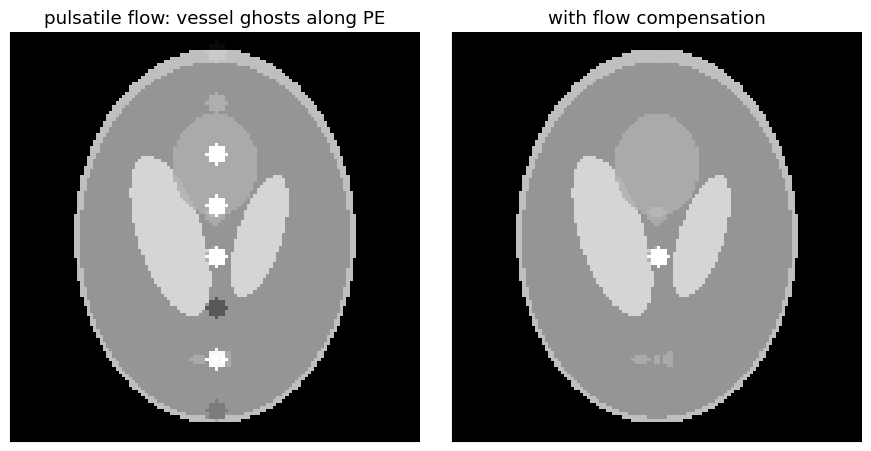

In [15]:
# Pulsatile flow: a small "vessel" whose phase varies from line to line with the cardiac cycle
Nf = 128
phf = mt.tissue_phantom(Nf)
base = phf["M0"] * (phf["labels"] > 0) * 0.5
yy_, xx_ = np.mgrid[0:Nf, 0:Nf]
vessel = ((yy_ - 70)**2 + (xx_ - 64)**2 <= 3**2) * 1.0
T_card, TR_f = 0.8, 0.1                             # heart period and TR [s] -> ghost spacing N TR / T = 16 px
jf = np.arange(Nf)
phase_j = 1.5 * np.sin(2 * np.pi * jf * TR_f / T_card)           # velocity-induced phase per line [rad]
K_flow = mt.fft2c(base) + mt.fft2c(vessel) * np.exp(1j * phase_j)[:, None]
K_flowcomp = mt.fft2c(base) + mt.fft2c(vessel)                     # flow compensated: no velocity phase
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
mt.show_image(mt.ifft2c(K_flow), ax=ax[0], vmax=0.6, title="pulsatile flow: vessel ghosts along PE")
mt.show_image(mt.ifft2c(K_flowcomp), ax=ax[1], vmax=0.6, title="with flow compensation")
plt.tight_layout(); plt.show()

The vessel (a small disk in the centre) is copied up and down along the PE (vertical) direction at multiples of $N\,TR/T_{card}$ = 16 pixels; the static tissue is unaffected. Flow-compensated gradients (zero first moment) remove the velocity phase.

**Better / worse (motion and flow):** worse with long scans, sequential PE ordering, long TR × periods matching, uncooperative patients, high resolution (smaller pixels = same motion is more pixels). **Mitigation:** breath-hold, respiratory gating/triggering or navigators, ECG gating, faster imaging (parallel imaging, single-shot), motion-robust trajectories (radial, PROPELLER/BLADE), flow compensation (gradient moment nulling), spatial saturation bands upstream, swapping PE/FE to move ghosts away from the region of interest, signal averaging (ghosts average down incoherently), prospective/retrospective motion correction.

## 5. EPI N/2 (Nyquist) ghost

**What you see:** a faint copy of the object shifted by **half the FOV** along PE (in EPI only), overlapping the image.

**Cause:** EPI acquires every other k-space line with the readout gradient reversed. Any mismatch between odd and even lines — gradient delays, eddy currents, timing of the ADC relative to the gradient, $B_0$ eddy currents — shifts the echo slightly in $k_x$, in opposite directions for odd and even lines. After a 1D FFT along $k_x$, a $k_x$ shift is a linear phase in $x$, so line $j$ gets the phase $(-1)^j\phi(x)$ with $\phi(x)=\phi_0+\phi_1x$.

**Math:** use $e^{i(-1)^j\phi}=\cos\phi+i(-1)^j\sin\phi$ and note that multiplying line $j$ by $(-1)^j=e^{i\pi j}$ shifts the image by $N_{PE}/2$ pixels:

$$\hat m(x,y)=\cos\phi(x)\,m(x,y)+i\sin\phi(x)\,m\!\left(x,\,y-\tfrac{FOV_{PE}}{2}\right)$$

In words: the image is slightly attenuated by $\cos\phi$, and a ghost of relative amplitude $|\sin\phi|$ appears shifted by half the FOV. A phase error of only 0.1 rad already gives a 10 % ghost.
Where: $\phi(x)$ [rad] = odd/even phase difference (half of it applied to each), $FOV_{PE}$ [m].

**Mitigation:** a **reference scan** (a few echoes acquired without phase encoding, built into every EPI sequence) measures $\phi(x)$, which is removed in the reconstruction; gradient delay calibration, eddy-current compensation; more advanced methods use both polarities ("dual-polarity GRAPPA").

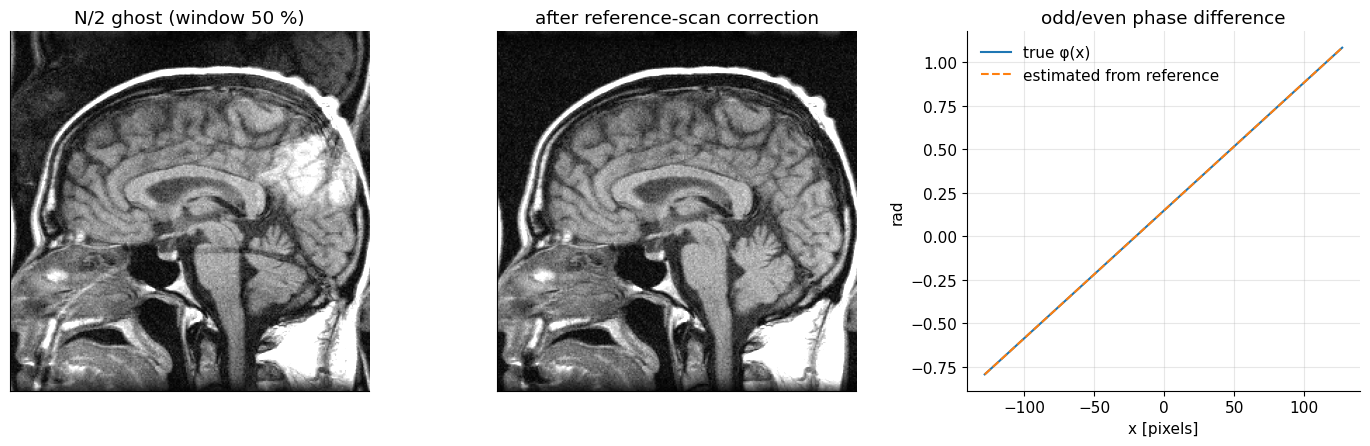

fit: phi0 = 0.150 rad (true 0.15), phi1 = 0.00736 rad/px (true 0.00736)


In [16]:
# N/2 ghost: alternate lines get +/- phi(x) in hybrid (x, ky) space
Nx_ = S[1]
x_pix = np.arange(Nx_) - Nx_ // 2
phi0, phi1 = 0.15, 2 * np.pi * 0.3 / Nx_               # constant [rad] + linear term (= 0.3-sample echo shift)
phi_x = phi0 + phi1 * x_pix
sign = np.where(np.arange(S[0]) % 2 == 0, 1.0, -1.0)    # (-1)^j

hybrid = mt.ifftc(kdata, axis=1)                        # FFT along readout only: (ky, x)
hybrid_err = hybrid * np.exp(1j * sign[:, None] * phi_x[None, :] / 2)
im_ghost = mt.ifftc(hybrid_err, axis=0)

# reference scan: the k_y = 0 line measured once with each readout polarity (no PE)
ref_even = hybrid[S[0] // 2] * np.exp(1j * phi_x / 2)
ref_odd = hybrid[S[0] // 2] * np.exp(-1j * phi_x / 2)
dphi = np.angle(ref_even * np.conj(ref_odd))            # measured phi(x), noisy where there is no signal
wts = np.abs(hybrid[S[0] // 2])**2
p_fit = np.polyfit(x_pix, dphi, 1, w=np.sqrt(wts))      # weighted linear fit: phi1, phi0
phi_est = np.polyval(p_fit, x_pix)
im_corr = mt.ifftc(hybrid_err * np.exp(-1j * sign[:, None] * phi_est[None, :] / 2), axis=0)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
mt.show_image(im_ghost, ax=ax[0], vmax=0.5 * vmax0, title="N/2 ghost (window 50 %)")
mt.show_image(im_corr, ax=ax[1], vmax=0.5 * vmax0, title="after reference-scan correction")
ax[2].plot(x_pix, phi_x, label="true φ(x)"); ax[2].plot(x_pix, phi_est, "--", label="estimated from reference")
ax[2].set_xlabel("x [pixels]"); ax[2].set_ylabel("rad"); ax[2].legend(); ax[2].set_title("odd/even phase difference")
plt.tight_layout(); plt.show()
print(f"fit: phi0 = {p_fit[1]:.3f} rad (true {phi0}), phi1 = {p_fit[0]:.5f} rad/px (true {phi1:.5f})")

The ghost is a half-FOV-shifted copy (here the top and bottom halves of the head appear superimposed at reduced intensity). The ghost is stronger on one side (where $|\phi(x)|$ is larger, because of the linear term). The reference-scan estimate of $\phi(x)$ removes it completely in this idealised (noise-free, no-$T_2^*$) case.

## 6. Unwanted signals — spike noise, zipper, overflow

### 6.1 Spike noise (herringbone / "corduroy")

**What you see:** a pattern of parallel stripes over the whole image (sometimes several overlapping patterns: herringbone), at a particular angle and spacing.

**Cause:** intermittent unwanted signals received during the acquisition — loose connections, broken components, static discharges (e.g. from dry air, gradient-coil vibration rubbing on cables), arcing — produce a spike: one (or a few) corrupted k-space samples.

**Math:** adding a single value $A$ at k-space position $\vec k_0=(k_{x0},k_{y0})$ adds its Fourier transform, a **plane wave**, to the image:

$$\hat m(\vec r)=m(\vec r)+A\,e^{i2\pi\vec k_0\cdot\vec r}$$

In words: a k-space spike = stripes over the entire image, with wavelength $1/|\vec k_0|$ and stripes perpendicular to $\vec k_0$; the farther the spike from the k-space centre, the finer the stripes.
Where: $A$ = spike amplitude (complex), $\vec k_0$ [m⁻¹] = its location.

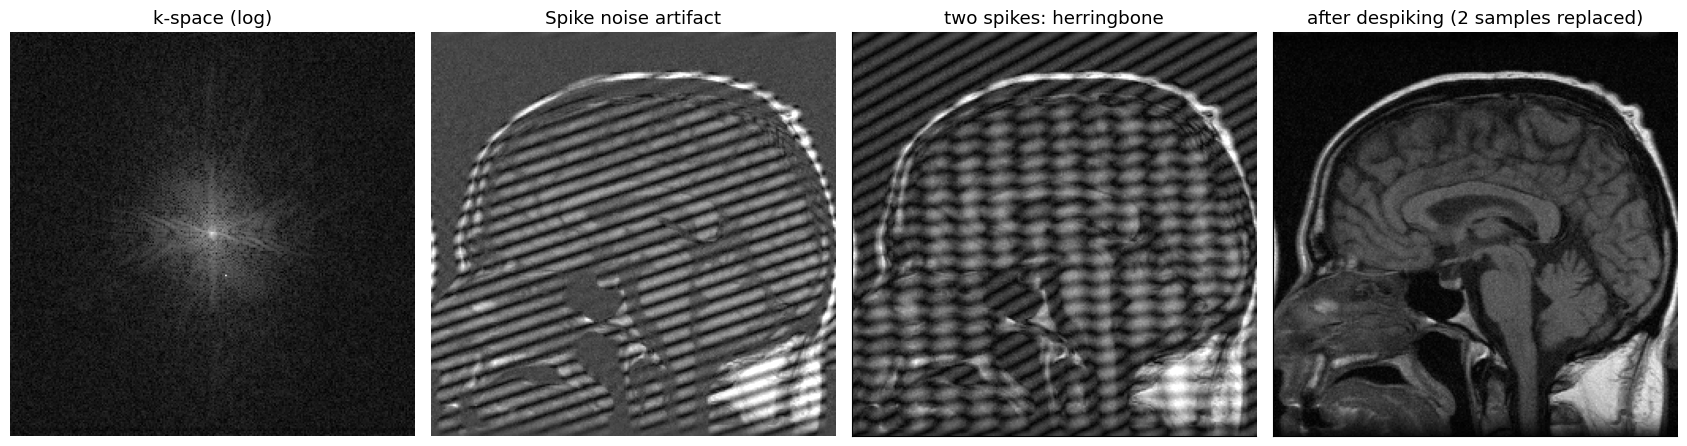

In [17]:
# Spike noise simulation (original): one corrupted sample, amplitude 2x the k-space maximum
spike_location = [0.6, 0.53]
data_spike = np.zeros_like(kdata)
data_spike[round(S[0] * spike_location[0]), round(S[1] * spike_location[1])] = kmax0 / .5
im_spike = mt.ifft2c(kdata + data_spike)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
show_pair(kdata + data_spike, "Spike noise artifact", axes=ax[:2])
# port of generate_image_artifacts.m: two spikes -> two stripe patterns ("herringbone")
data_2spikes = kdata.copy()
data_2spikes[128, 115] += kmax0
data_2spikes[152, 128] += kmax0
mt.show_image(mt.ifft2c(data_2spikes), ax=ax[2], vmax=vmax0, title="two spikes: herringbone")

# Correction: detect outliers relative to the local k-space magnitude and replace them
from scipy.ndimage import median_filter
def despike(K, thresh=8.0):
    mag = np.abs(K)
    local = median_filter(mag, size=5)                       # local typical magnitude
    bad = mag > thresh * (local + 1e-3 * mag.max())
    bad[S[0] // 2 - 2:S[0] // 2 + 3, S[1] // 2 - 2:S[1] // 2 + 3] = False   # never touch the true centre peak
    Kc = K.copy()
    Kc[bad] = (median_filter(K.real, size=3) + 1j * median_filter(K.imag, size=3))[bad]
    return Kc, bad
K_fixed, bad = despike(data_2spikes)
mt.show_image(mt.ifft2c(K_fixed), ax=ax[3], vmax=vmax0, title=f"after despiking ({bad.sum()} samples replaced)")
plt.tight_layout(); plt.show()

A single spike gives one set of diagonal stripes covering the whole image; two spikes give two overlapping patterns. Because the corruption is so localised in k-space, a simple outlier detector (sample ≫ local median) finds and replaces the bad samples, removing the artifact.

**Mitigation:** find the hardware cause (service engineer: loose connectors, cracked solder joints, light bulbs, dry air → humidify); retrospectively, k-space despiking as above.

### 6.2 RF interference / zipper

**What you see:** a narrow line (or band) of noise-like signal ("zipper") running across the whole image **along the PE direction**, at a fixed position along the readout.

**Cause:** unwanted frequencies received during the acquisition. These can come from RF interference from other devices, such as lights or electronics in the room, patient monitoring equipment, or sources outside the scan room — especially if the door of the RF-shielded room (Faraday cage) is not closed.

**Math:** a continuous interfering tone at frequency $f_{int}$ appears, after demodulation, at offset $\Delta f_{int}=f_{int}-f_0$, i.e. in every readout as $A_j\,e^{-i2\pi\Delta f_{int}t}$. Along the readout it is a single frequency → a single **$x$ position**, $x_{int}=\frac{\Delta f_{int}}{BW_{read}}FOV_{FE}$ (the same formula as off-resonance). Because the interference is not synchronised with the sequence, its amplitude/phase $A_j$ is effectively random from line to line → spread over all $y$ (noise-like) → a line along PE.

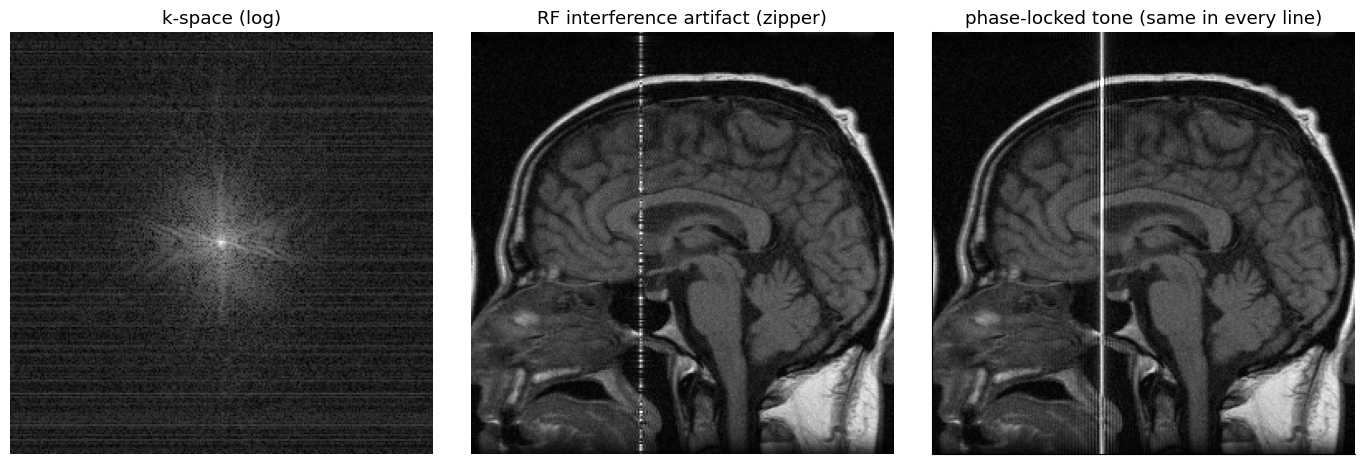

tone at 0.10 cycles/sample -> x offset = 25.6 pixels from centre; with BW_read = 64 kHz that is Δf_int = 6.4 kHz


In [18]:
# RF interference (original): amplitude-modulated tone along the readout, random amplitude per PE line
rng = np.random.default_rng(0)
relative_RF_frequency = 0.2
rfint = np.exp(1j * 2 * np.pi * np.arange(S[1]) / S[1] * S[1] * relative_RF_frequency / 2) * kmax0 / S[1] / 3
data_rfint = rng.standard_normal((S[0], 1)) * rfint[None, :]        # random amplitude for each PE line
# variant: same tone but phase-locked (identical in every line) -> a single dot, not a zipper
data_locked = np.zeros_like(kdata)
data_locked[S[0] // 2, :] = rfint * S[0] / 10                        # coherent: all energy in one ky
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
show_pair(kdata + data_rfint, "RF interference artifact (zipper)", axes=ax[:2])
mt.show_image(mt.ifft2c(kdata + data_locked), ax=ax[2], vmax=vmax0, title="phase-locked tone (same in every line)")
plt.tight_layout(); plt.show()
BWread_ex = 64e3
print(f"tone at {relative_RF_frequency/2:.2f} cycles/sample -> x offset = {S[1]*relative_RF_frequency/2:.1f} pixels "
      f"from centre; with BW_read = {BWread_ex/1e3:.0f} kHz that is Δf_int = {relative_RF_frequency/2*BWread_ex/1e3:.1f} kHz")

The random-amplitude interference produces a vertical noisy line (the zipper) at a fixed readout position 25.6 pixels right of centre. A tone that is perfectly identical in every line would add to only *one* $k_y$ value and give a sharp line of uniform intensity — real interference is not synchronised, hence the noisy zipper. (A different kind of "zipper" at the centre of the readout comes from RF feedthrough or imperfectly spoiled FID/stimulated echoes, which are at the transmit frequency.)

**Mitigation:** close the scan-room door, remove/replace electronic devices, check the RF shielding (Faraday cage) and penetration panel filters; the artifact's $x$ position tells the engineer the interfering frequency.

### 6.3 Receiver overflow (clipping)

When the signal at the k-space centre exceeds the input range of the receiver/ADC (receiver gain set too high), the largest samples are **clipped**. Clipping affects the strongest, i.e. the *central* k-space samples, so low spatial frequencies are damaged: the image looks washed out, edge-enhanced, with a strange overall intensity. Port of the clipping example of `generate_image_artifacts.m`: k-space magnitudes above 20 % of the maximum are clipped to 20 %.

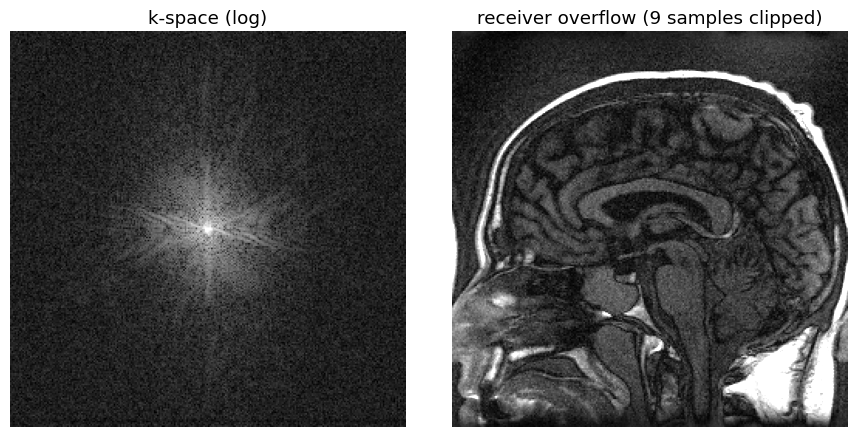

In [19]:
th = 0.2
data_clip = kdata.copy()
big = np.abs(kdata) > th * kmax0
data_clip[big] = kdata[big] / np.abs(kdata[big]) * th * kmax0          # keep the phase, clip the magnitude
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
show_pair(data_clip, f"receiver overflow ({big.sum()} samples clipped)", axes=ax, vmax=0.5 * vmax0)
plt.tight_layout(); plt.show()

Only a few dozen central samples are clipped, but they carry most of the image energy: the result is a "high-pass filtered" image. **Mitigation:** correct receiver-gain calibration (prescan), which is automatic on modern scanners; high-dynamic-range receivers.

## 7. MRI hardware limitations — RF shading, gradient non-linearity

### 7.1 RF (B1) shading

**What you see:** smooth, large-scale intensity variations: a bright centre and dark periphery in the abdomen at 3 T ("dielectric effect"), brightness near surface coils, dark bands.

**Cause:** the propagation of radiofrequency waves in tissue, as well as inhomogeneous RF coils, lead to variations in intensity or shading across the image.

* **Transmit ($B_1^+$):** when transmitting RF pulses, there is some variation in the RF amplitude across the body. This is partially due to inhomogeneous transmit coils, but is fundamentally limited by the wavelength of the RF in tissue: $\lambda=c/(f_0\sqrt{\varepsilon_r})$ with relative permittivity $\varepsilon_r\approx50$–80, giving ≈ 50 cm at 1.5 T, ≈ 27–33 cm at 3 T and ≈ 12 cm at 7 T — comparable to the body, so standing-wave patterns form. Because this wavelength is set by the dielectric constant of tissue, this is sometimes referred to as **dielectric shading**. The variation in RF amplitude leads to variations in **flip angle**, $\theta(\vec r)=b_1(\vec r)\,\theta_{nom}$, which change the image intensity. For a spin echo with both pulses scaled: $S\propto\sin(b_1\tfrac{\pi}{2})\,\sin^2(b_1\tfrac{\pi}{2})=\sin^3(b_1\tfrac{\pi}{2})$ (the refocusing efficiency of a pulse of angle $\theta_2$ is $\sin^2(\theta_2/2)$).
* **Receive ($B_1^-$, $C_n$):** RF receive coil arrays are designed to provide high sensitivity and approximately uniform coverage. However, the arrays have varying sensitivity across the body, being most sensitive close to each element, leading to variations in image intensity.

**Math:** both act as a smooth **multiplicative** field on the image (not a convolution): $\hat m(\vec r)=m(\vec r)\,f_{tx}(b_1(\vec r))\,|C(\vec r)|$.

RF shading from these sources is typically corrected by applying a weighting to the originally reconstructed image to create more uniform image intensities (vendor "prescan normalize"/"intensity correction", or bias-field estimation like N4). Below, a crude **homomorphic** correction: estimate the bias as a heavily smoothed version of the image (inside the object) and divide by it.

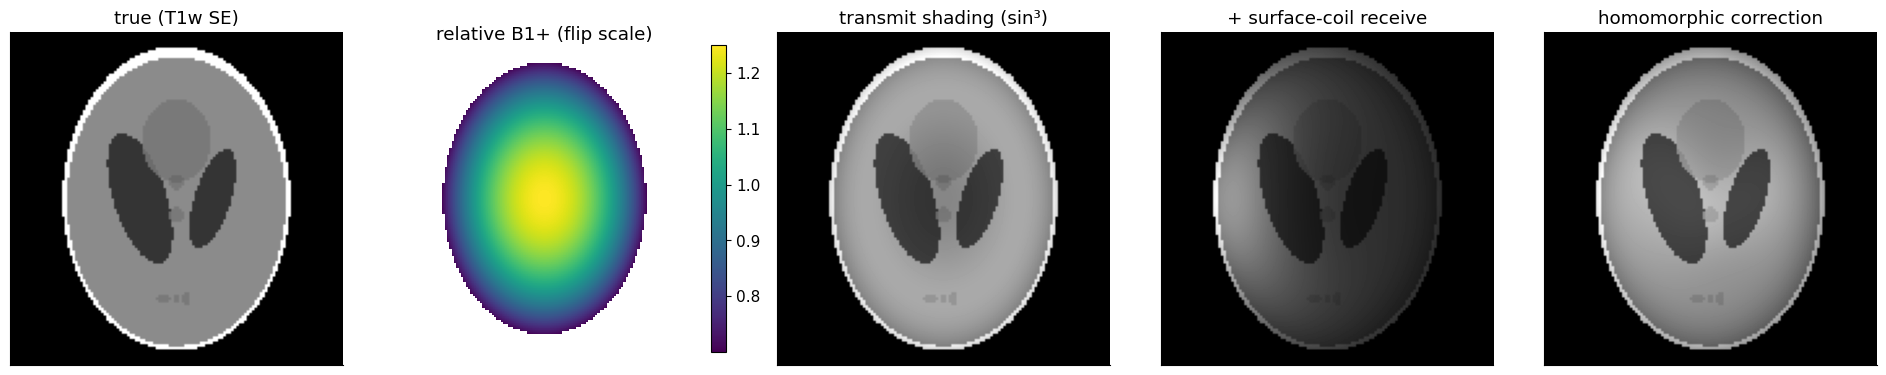

In [20]:
from scipy.ndimage import gaussian_filter
Nb = 128
phb = mt.tissue_phantom(Nb)
obj = mt.spin_echo_signal(15e-3, 0.6, phb["T1"], phb["T2"], phb["M0"]) * (phb["labels"] > 0)   # T1w spin echo
yy_, xx_ = np.mgrid[1:-1:Nb * 1j, -1:1:Nb * 1j]
b1 = 1.25 - 0.55 * (xx_**2 / 0.69**2 + yy_**2 / 0.92**2)          # toy 3T "central brightening" B1+ pattern
tx = np.sin(b1 * np.pi / 2)**3                                     # spin echo: sin^3 of the scaled flip angle
rx = 1 / (1 + ((xx_ + 1.1)**2 + yy_**2) / 0.5)                     # one surface coil on the left (toy profile)
rx /= rx[phb["labels"] > 0].max()
shaded = obj * tx * rx
mask = phb["labels"] > 0
bias = gaussian_filter(shaded * mask, 12) / (gaussian_filter(mask * 1.0, 12) + 1e-6)
corrected = np.where(mask, shaded / (bias + 1e-6), 0)
corrected *= np.median(obj[mask]) / np.median(corrected[mask])
fig, ax = plt.subplots(1, 5, figsize=(19, 4))
mt.show_image(obj, ax=ax[0], title="true (T1w SE)")
im_ = ax[1].imshow(np.where(mask, b1, np.nan), cmap="viridis"); ax[1].axis("off"); ax[1].set_title("relative B1+ (flip scale)")
plt.colorbar(im_, ax=ax[1], fraction=0.046)
mt.show_image(obj * tx, ax=ax[2], title="transmit shading (sin³)")
mt.show_image(shaded, ax=ax[3], title="+ surface-coil receive")
mt.show_image(corrected, ax=ax[4], vmax=obj.max(), title="homomorphic correction")
plt.tight_layout(); plt.show()

A ±30 % flip-angle variation already changes the spin-echo signal strongly (sin³!); the surface coil adds a left–right gradient. The homomorphic correction flattens the large-scale shading but also slightly alters genuine large-scale contrast — real bias-field correction methods are more careful.

**Better / worse:** transmit shading worse at higher $B_0$ (3 T body, 7 T head), large FOV, large patients, ascites; spin echo/FSE more than low-flip GRE. Receive shading worse with surface coils and small elements. **Mitigation:** RF shimming / parallel transmission (multiple transmit channels with individually tuned amplitude/phase), dielectric pads (high-permittivity material), adiabatic (B1-insensitive) pulses, $B_1$ mapping and flip-angle correction, intensity normalisation (prescan normalize, N4).

### 7.2 Gradient non-linearity

**What you see:** geometric distortion that increases toward the edges of a large FOV (barrel or pincushion warping, straight structures bent), especially far from isocentre and along the bore axis (z).

**Cause:** gradient coils in MRI are designed to create linear changes in the magnetic field. However, they are not perfect, particularly near the edges and closer to the open ends of the magnet bore — short, wide-bore and high-performance gradient coils trade linearity for speed and patient space ([Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)). In these regions the gradients are non-linear. Since MRI assumes linear gradient encoding, this non-linearity results in distortion of the images.

**Math (toy model):** with $B_z(x)=B_0+G\,(x+\alpha\,x^3/R_0^2)$, a spin at $x$ precesses at the frequency the reconstruction assigns to position

$$x'=x\left(1+\alpha\frac{x^2}{R_0^2}\right)$$

In words: positions are mapped (warped) non-linearly; the image intensity is additionally scaled by $1/|dx'/dx|$ (signal from a stretched region is spread over more pixels).
Where: $x'$ = apparent position [m]; $\alpha$ = non-linearity coefficient (negative = gradient weaker at the edges → barrel/compression); $R_0$ = reference radius [m].

This is corrected by using measurements (spherical-harmonic models) of the fields created by the gradient coils to undo the distortions of the image ("gradwarp", "distortion correction 2D/3D"), which every vendor applies by default — it matters for radiotherapy planning and surgical navigation, where geometric accuracy of ~1 mm is required.

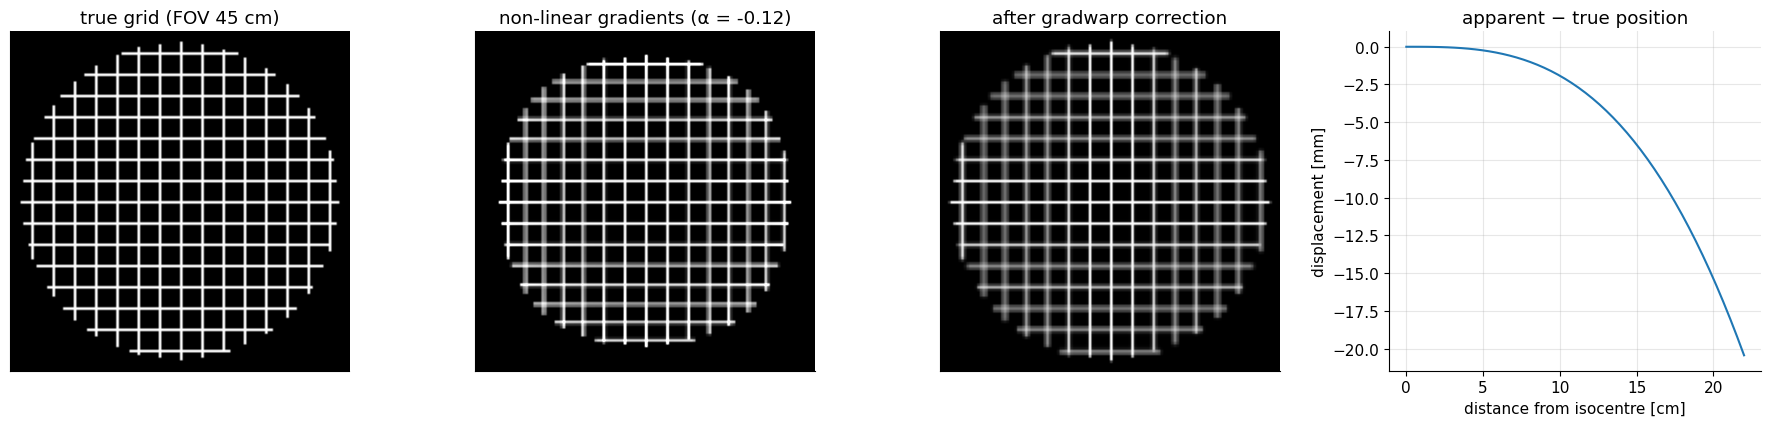

In [21]:
from scipy.ndimage import map_coordinates
Ng = 128
FOVg = 0.45                                         # large body FOV [m]
xg = (np.arange(Ng) - Ng // 2 + 0.5) * FOVg / Ng    # pixel positions [m]
grid = np.zeros((Ng, Ng))
grid[::8, :] = 1; grid[:, ::8] = 1                  # grid phantom (lines every 8 pixels = 2.8 cm)
grid *= (np.add.outer(xg**2, xg**2) < (0.21)**2)
alpha, R0 = -0.12, 0.25

def warp_fwd(x):            # true position -> apparent position
    return x * (1 + alpha * x**2 / R0**2)

# Distorted image: for each apparent pixel x', find the true x (invert the monotonic map by interpolation)
x_true_of_app = np.interp(xg, warp_fwd(xg), xg)
jac = 1 + 3 * alpha * x_true_of_app**2 / R0**2      # dx'/dx at the true position
idx = (x_true_of_app / (FOVg / Ng)) + Ng // 2 - 0.5 # fractional pixel index
IY, IX = np.meshgrid(idx, idx, indexing="ij")
distorted = map_coordinates(grid, [IY, IX], order=1) / np.outer(jac, jac)
# Correction (gradwarp): resample the distorted image at the apparent positions of the true pixel grid
idx_app = warp_fwd(xg) / (FOVg / Ng) + Ng // 2 - 0.5
IY2, IX2 = np.meshgrid(idx_app, idx_app, indexing="ij")
corrected_g = map_coordinates(distorted * np.outer(jac, jac), [IY2, IX2], order=1)

fig, ax = plt.subplots(1, 4, figsize=(18, 4.4))
mt.show_image(grid, ax=ax[0], title="true grid (FOV 45 cm)")
mt.show_image(distorted, ax=ax[1], vmax=1, title=f"non-linear gradients (α = {alpha})")
mt.show_image(corrected_g, ax=ax[2], vmax=1, title="after gradwarp correction")
xs_cm = np.linspace(0, 0.22, 50)
ax[3].plot(xs_cm * 100, (warp_fwd(xs_cm) - xs_cm) * 1e3)
ax[3].set_xlabel("distance from isocentre [cm]"); ax[3].set_ylabel("displacement [mm]")
ax[3].set_title("apparent − true position")
plt.tight_layout(); plt.show()

The grid is compressed toward the edges (barrel distortion, displacement ≈ 1 cm at 20 cm from isocentre in this toy model) and the lines near the edge appear brighter (signal from a larger true region is packed into fewer pixels). Knowing the field model, the correction restores the geometry (slightly blurred by interpolation).

## 8. Parallel imaging artifacts

In parallel imaging, k-space is purposefully undersampled, resulting in aliasing that is removed using the coil sensitivities in the image reconstruction (see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)). However, failures can lead to **residual aliasing**. These can be the result of inconsistencies in the coil sensitivity maps (e.g. patient motion between the calibration scan and the scan, maps that do not cover the whole object, FOV smaller than the object), or setting the acceleration factor too high. Even when the unfolding is perfect, noise is amplified by the **g-factor**, $SNR_{acc}=SNR_{full}/(g\sqrt R)$, appearing as spatially varying noise, worst where the aliased pixels have similar coil sensitivities (often the centre).

![Axial abdomen image with unresolved aliasing with parallel imaging](../images/artifacts/abdomen_aliasing_parallel-imaging.png)

*Axial abdomen image showing an aliasing artifact (yellow arrows) due to a parallel imaging failure.*

**Math (SENSE):** with $R$-fold undersampling along $y$, each pixel of the reduced-FOV image of coil $n$ is a sum of $R$ object points $y_1,\dots,y_R$ spaced $FOV/R$ apart:

$$a_n(x,y)=\sum_{l=1}^{R}C_n(x,y_l)\,m(x,y_l)\quad\Longleftrightarrow\quad\vec a=\mathbf C\,\vec m$$

In words: for every aliased pixel we have $N_c$ equations (one per coil) for $R$ unknowns; if $N_c\ge R$ and the sensitivities differ enough, we can solve for $\vec m$ (least squares: $\hat{\vec m}=(\mathbf C^H\mathbf C)^{-1}\mathbf C^H\vec a$).
Where: $\vec a$ = vector of the $N_c$ aliased coil values; $\mathbf C$ = $N_c\times R$ sensitivity matrix; $^H$ = conjugate transpose. If the $\mathbf C$ used in the reconstruction is wrong, the solution mixes the aliased points → residual aliasing. The full SNR derivation is in [Advanced SNR](J4_Advanced_SNR.ipynb).

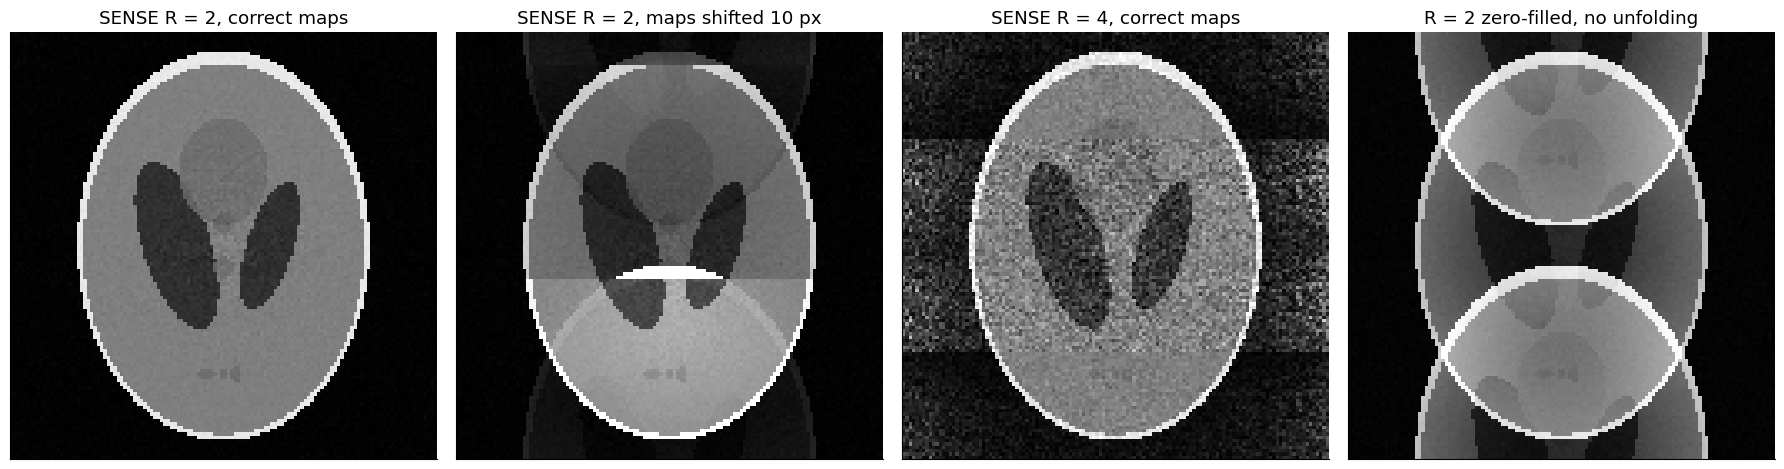

In [22]:
# Toy 8-coil array and a SENSE reconstruction (rows = PE, undersampled)
Np = 128
php = mt.tissue_phantom(Np)
m_true = mt.spin_echo_signal(15e-3, 0.6, php["T1"], php["T2"], php["M0"]) * (php["labels"] > 0)
yy_, xx_ = np.mgrid[1:-1:Np * 1j, -1:1:Np * 1j]
Nc = 8
ang = 2 * np.pi * np.arange(Nc) / Nc
coils = np.array([np.exp(-((xx_ - 1.1 * np.cos(a))**2 + (yy_ - 1.1 * np.sin(a))**2) / 0.6)
                  * np.exp(1j * (np.cos(a) * xx_ + np.sin(a) * yy_) * 1.5) for a in ang])   # toy sensitivities
coils /= np.sqrt((np.abs(coils)**2).sum(0)).max()

def sense_recon(K_coils, C_maps, R):
    """SENSE unfolding along rows. K_coils: (Nc, N, N) fully sampled k-space; uses every R-th row."""
    Nc_, N, _ = K_coils.shape
    a = mt.ifft2c(K_coils[:, ::R, :]) * np.sqrt(R)              # reduced-FOV aliased coil images (Nc, N/R, N)
    n_red = N // R
    rows = np.arange(n_red) + N // 2 - n_red // 2               # full-FOV row of each reduced-FOV row
    out = np.zeros((N, N), complex)
    ys = (rows[:, None] + np.arange(R)[None, :] * n_red) % N    # the R aliased rows for each reduced row
    Cm = C_maps[:, ys, :]                                       # (Nc, n_red, R, N)
    Cm = np.moveaxis(Cm, 0, -1).transpose(0, 2, 3, 1)           # (n_red, N, Nc, R)
    A = np.moveaxis(a, 0, -1)                                   # (n_red, N, Nc)
    CH = np.conj(np.swapaxes(Cm, -1, -2))                       # (n_red, N, R, Nc)
    lhs = CH @ Cm + 1e-6 * np.eye(R)
    rhs = CH @ A[..., None]
    sol = np.linalg.solve(lhs, rhs)[..., 0]                     # (n_red, N, R)
    for l in range(R):
        out[ys[:, l], :] = sol[:, :, l]
    return out

rng = np.random.default_rng(3)
K_coils = mt.fft2c(coils * m_true[None])
noise_sigma = 0.004
K_noisy = mt.add_complex_noise(K_coils, noise_sigma, rng=rng)
coils_moved = np.roll(coils, 10, axis=1)                        # maps acquired before the patient moved 10 px
recons = [("SENSE R = 2, correct maps", sense_recon(K_noisy, coils, 2)),
          ("SENSE R = 2, maps shifted 10 px", sense_recon(K_noisy, coils_moved, 2)),
          ("SENSE R = 4, correct maps", sense_recon(K_noisy, coils, 4)),
          ("R = 2 zero-filled, no unfolding", np.sqrt((np.abs(mt.ifft2c(np.where((np.arange(Np) % 2 == 0)[None, :, None], K_noisy, 0)))**2).sum(0)) * 2)]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
for a_, (name, img) in zip(ax, recons):
    mt.show_image(img, ax=a_, vmax=1.1 * m_true.max(), title=name)
plt.tight_layout(); plt.show()

With correct maps, $R=2$ unfolds cleanly. With maps that no longer match the anatomy (patient moved 10 pixels between calibration and scan), residual aliasing appears half a FOV away from the true structures — the same appearance as the clinical example. At $R=4$ the unfolding is still correct but the image is visibly **noisier in the centre** (g-factor), where the four aliased points see similar combinations of the coils. The last panel shows what the scanner would see without any unfolding (plain $R=2$ aliasing).

**Better / worse:** worse with high $R$ (especially $R$ close to the number of coil elements along that direction), few coil elements, motion between calibration and scan, FOV smaller than the object (aliasing in the *calibration* data). **Mitigation:** lower $R$, coil arrays with many elements along the PE direction, integrated (auto-)calibration (GRAPPA/ESPIRiT with ACS lines acquired during the scan), CAIPIRINHA sampling in 3D/multiband, regularised reconstructions.

## 9. Summary table

| Artifact | Source | Appearance | Math (signal-equation / PSF view) | Worse with | What to do | Direction |
|---|---|---|---|---|---|---|
| Aliasing (wrap) | sequence: $FOV$ < object | fold-over from the opposite side | sampling at $\Delta k$ → periodic PSF, replicas every $1/\Delta k$ | small $FOV_{PE}$, large patient | larger FOV, phase oversampling, swap PE/FE, sat bands | PE (and 2nd PE in 3D) |
| Gibbs ringing | sequence: truncated k-space | ripples parallel to sharp edges, ~9 % overshoot | $W=\mathrm{rect}$ → sinc PSF | low matrix, high-contrast edges, partial Fourier | larger matrix, k-space window (Hamming…) | both |
| Partial volume / boundary (India ink) | sample + sequence | faint small objects; dark lines at fat–water or IR boundaries | complex sum within voxel, phases cancel | large voxels/thick slices; opposed-phase TE; TI between null points | smaller voxels, in-phase TE, fat sat, phase-sensitive IR | – |
| Fat (chemical-shift) displacement | sample: $\Delta f_{cs}$ | fat shifted: dark gap / bright band | phase $e^{-i2\pi\Delta f\upsilon(k)}$, linear → shift $\Delta f/BW_{pix}$ px | high $B_0$, low BW, EPI | higher BW, fat sat, Dixon, swap PE/FE, PI for EPI | FE (2DFT), PE (EPI) |
| Off-resonance distortion | sample: susceptibility, shim | stretch / compression, pile-up | local shift $\Delta f_r(\vec r)/BW_{pix}$, Jacobian intensity | high $B_0$, air/metal, EPI, low BW | shim, higher BW, PI, segmentation, reversed-PE / field-map correction | FE (2DFT), PE (EPI) |
| Slice displacement | sample: $\Delta f$ | wrong / bent slice | slice shift $\Delta z\,\Delta f/BW_{rf}$ | low $BW_{rf}$, metal | higher $BW_{rf}$, 3D, SEMAC | slice |
| $T_2^*$ signal loss | sample: susceptibility | signal voids near air/metal | intravoxel dephasing $\approx|\mathrm{sinc}(\delta f\,TE)|$ | long TE, thick slices, GRE, high $B_0$ | spin echo, short TE, thin slices, z-shim | – |
| Motion (periodic) | sample | discrete ghosts | line-to-line phase/amplitude modulation → copies at $N\,TR/T_{motion}$ px | long scans, breathing, cardiac | gating, breath-hold, navigators, swap PE/FE, averaging | PE |
| Motion (random) | sample | smear / diffuse ghosts | incoherent modulation along $k_y$ | uncooperative patients, long scans | faster scans, PROPELLER/radial, motion correction | PE |
| Flow | sample | vessel ghosts; inflow brightness | velocity phase $\gamma v\int Gt\,dt$ per line | pulsatile flow, large first moments | flow compensation, sat bands, gating | PE |
| N/2 (Nyquist) ghost | system/sequence: EPI odd/even mismatch | copy shifted by FOV/2 | $e^{i(-1)^j\phi(x)}$ → $\cos\phi\,m+i\sin\phi\,m(y-FOV/2)$ | eddy currents, gradient delays, oblique slices | reference-scan phase correction, calibration | PE (EPI) |
| Spike / herringbone | system: discharges, bad contacts | stripes over the whole image | added $A\,\delta(\vec k-\vec k_0)$ → plane wave | dry air, damaged hardware | fix hardware; despiking | – |
| RF interference / zipper | system: external RF | line of noise at fixed readout position | added tone $e^{-i2\pi\Delta f_{int}t}$, random per line | open door, electronics in room | close door, shielding, remove devices | along PE at one FE position |
| Receiver overflow | system: gain too high | washed-out, edge-enhanced image | clipped central k-space | wrong prescan | redo prescan / gain | – |
| B1 (dielectric) / coil shading | system + sample | smooth brightness variations | multiplicative $f(b_1)\,|C|$ | high $B_0$, large FOV/body, SE/FSE, surface coils | RF shimming/pTx, dielectric pads, adiabatic pulses, intensity correction | – |
| Gradient non-linearity | system | geometric warp at FOV edges | wrong encoding $x'=x(1+\alpha x^2/R_0^2)$ | large FOV, off-isocentre, short/wide gradient coils | gradwarp correction, position at isocentre | all |
| Parallel imaging | sequence/recon | residual aliasing; noise enhancement (g-factor) | wrong $\mathbf C$ in $\vec a=\mathbf C\vec m$; $SNR/(g\sqrt R)$ | high $R$, motion, few coils | lower $R$, auto-calibration, CAIPI, more coils | PE |

Other artifacts not simulated here: eddy-current distortions (diffusion EPI), magic-angle effect (tendons at 55° to $B_0$ appear bright on short-TE images), banding in bSSFP (off-resonance), crisscross/"moiré" from field-of-view edges in GRE, and susceptibility artifacts from metal implants.

## Key takeaways

* Most artifacts are (i) a **multiplicative** k-space weighting → convolution with a PSF, (ii) **incomplete sampling** → replicas, (iii) something **added** to k-space → its FT added to the image, or (iv) wrong **encoding** → warping.
* Slow, line-to-line inconsistencies (motion, flow, hardware drifts, EPI odd/even errors) show up along **phase encoding**; effects acting within the readout (off-resonance, chemical shift) along **readout** in 2DFT but along **PE in EPI**.
* Shifts in pixels = Δf / bandwidth per pixel: fat is 1–4 px in 2DFT but tens of px in EPI; distortions near air–tissue interfaces scale the same way.
* Ghost spacing for periodic motion is $N_{PE}\,TR/T_{motion}$ pixels; EPI Nyquist ghosts sit at FOV/2 with amplitude ≈ $|\sin\phi|$.
* Spikes → stripes, tones → zippers; clipping damages low spatial frequencies.
* $B_1$ shading and gradient non-linearity are system effects that are routinely corrected in software; parallel imaging trades scan time for residual-aliasing risk and g-factor noise.

## Check your understanding

1. A sagittal knee image shows a ghost of the popliteal artery repeating every 20 pixels above and below it. In which direction is phase encoding, and what is the cause?

<details><summary>Answer</summary>

The ghosts lie along the PE direction (vertical here). They come from pulsatile arterial flow: the vessel's phase/amplitude changes from line to line with the cardiac cycle, so its signal is copied at multiples of $N_{PE}TR/T_{card}$ pixels. Flow compensation, saturation bands, or swapping PE/FE (to move ghosts away from the anatomy of interest) help.

</details>

2. You double the receiver bandwidth of a 2DFT scan. What happens to the chemical-shift displacement and to the SNR?

<details><summary>Answer</summary>

The displacement (in pixels, $\Delta f/BW_{pix}$) halves. SNR drops by $\sqrt2$ because the noise bandwidth doubles (equivalently, the readout time halves).

</details>

3. Why does motion along the *readout* direction still produce ghosts along the *phase-encoding* direction?

<details><summary>Answer</summary>

Within one readout (a few ms) the object hardly moves, so each line is internally consistent. But different lines are acquired at different times with different displacements; the resulting phase $e^{-i2\pi k_xd_j}$ varies from line to line, i.e. as a function of $k_y$. Variation along $k_y$ produces artifacts along $y$ (PE).

</details>

4. An EPI image shows a ghost at half the FOV with ~5 % of the image intensity. Estimate the odd/even phase error.

<details><summary>Answer</summary>

Ghost amplitude ≈ $|\sin\phi|$ → $\phi\approx0.05$ rad ≈ 3°. Such a small error is typical of residual eddy currents or a gradient delay of a fraction of a dwell time; reference-scan correction removes it.

</details>

5. A spike appears in k-space at $(k_{x0},k_{y0})=(0,\ 20\Delta k)$. What does the image artifact look like?

<details><summary>Answer</summary>

A plane wave $e^{i2\pi k_{y0}y}$: horizontal stripes (constant along $x$) with wavelength $1/k_{y0}=FOV/20$, i.e. 20 stripe periods across the FOV in the PE direction, superimposed on the whole image.

</details>

6. Why does fat appear shifted by 28 pixels in a 3 T single-shot EPI ($t_{esp}$ = 0.5 ms, $N_{PE}$ = 128), and what are three ways to reduce it?

<details><summary>Answer</summary>

Shift = $\Delta f\,N_{PE}\,t_{esp}$ = 447 Hz × 128 × 0.5 ms ≈ 28.6 pixels. Reduce by fat suppression (removes the fat signal), parallel imaging $R$ (divides the shift by $R$), shorter echo spacing, fewer PE lines / segmented EPI.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Artifacts". Changes: added for every artifact the math (PSF/signal equation), better/worse parameters and mitigations; new simulations (FOV fold-over, truncation on real data, partial volume/India ink and IR boundaries, susceptibility distortion and signal voids with an explicit forward model, periodic/random/readout-direction motion and flow ghosts, EPI N/2 ghost with reference correction, herringbone and despiking, clipping, B1 shading with correction, gradient non-linearity with gradwarp, SENSE failures and g-factor); ported `generate_image_artifacts.m` and `phase_encoding_aliasing.m`; completed the unfinished IR sentence; extended summary table; fixed typos ("suscpetibility", "Pediodic", "arrhytthmias", "abomdinal", "brian", "disortions").*